## Cell 1: Environment Configuration & Library Imports


In [1]:
from tensorflow.keras import backend as K
import gc

K.clear_session()
gc.collect()

2026-09-21 17:29:19.534793: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-09-21 17:29:19.534901: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-09-21 17:29:19.534944: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-09-21 17:29:19.542708: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-09-21 17:29:20.467548: W tensorflow/compiler/

0

In [2]:
import os
import sys
import math
import time
import json
import glob
import random
import datetime
from dataclasses import dataclass, field
from typing import List, Tuple, Dict, Any, Optional, Union

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set seeds for deterministic reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

# Configure GPU memory growth to prevent out-of-memory errors
physical_gpus = tf.config.list_physical_devices("GPU")
print(f"TensorFlow version: {tf.__version__}")
print(f"Available GPUs: {len(physical_gpus)}")
for gpu in physical_gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
        print(f"  Configured memory growth for: {gpu.name}")
    except RuntimeError as e:
        print(f"  Could not configure {gpu.name}: {e}")

# Plotting style setup
plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)
plt.rcParams["font.size"] = 11
plt.rcParams["figure.dpi"] = 120
print("Environment initialized successfully.")

TensorFlow version: 2.14.1
Available GPUs: 1
  Configured memory growth for: /physical_device:GPU:0
Environment initialized successfully.


2026-09-21 17:29:22.162805: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:894] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-09-21 17:29:22.195724: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:894] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-09-21 17:29:22.196037: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:894] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysf

## Cell 2: Hyperparameters & Configuration Dataclasses


In [3]:
@dataclass
class HorizonConfig:
    horizon_name: str = "15min"  # 15-minute forecast horizon
    lead_time_minutes: int = 15  # 15 minutes ahead
    hist_frames: int = 8  # 8 frames * 2 min = 16 minutes history
    fut_frames: int = 8  # 8 future frames * 2 min = 16 minutes (~15 min horizon)
    cadence_minutes: int = 2  # 2-minute sampling of the 1-minute native records
    window_sizes: List[int] = field(
        default_factory=lambda: [1, 4, 8]
    )  # RS-PV-MMA window sizes across scales [2, 3, 4]
    ddim_steps: int = 50  # Default DDIM sampling steps
    dpm_solver_steps: int = 50  # Backward compatibility alias
    batch_size: int = 8  # Batch size for training/inference
    learning_rate: float = 2e-4
    checkpoint_dir: str = "checkpoints/horizon_15m"
    log_dir: str = "logs/tensorboard/horizon_15m"


CONFIG_15M = HorizonConfig(
    horizon_name="15min",
    lead_time_minutes=15,
    hist_frames=8,
    fut_frames=8,
    window_sizes=[1, 4, 8],
    ddim_steps=50,
    dpm_solver_steps=50,
    batch_size=8,
    checkpoint_dir="checkpoints/horizon_15m",
    log_dir="logs/horizon_15m",
)

CONFIG = CONFIG_15M
ALL_CONFIGS = {"15min": CONFIG_15M}

# Global physical constants
PV_RATED_CAPACITY_KW = 30.0  # 30 kW Stanford rooftop array
IMAGE_RESOLUTION = (64, 64, 3)  # 64x64 RGB sky images
DIFFUSION_STEPS_T = 1000  # DDIM / DDPM forward training steps

print("15-Minute Horizon DDIM Configuration initialized:")
print(
    f"  [{CONFIG_15M.horizon_name}] hist={CONFIG_15M.hist_frames} frames, "
    f"fut={CONFIG_15M.fut_frames} frames (lead time = {CONFIG_15M.lead_time_minutes} min), "
    f"total sequence={CONFIG_15M.hist_frames + CONFIG_15M.fut_frames} frames, "
    f"RS-PV-MMA windows={CONFIG_15M.window_sizes}, batch size={CONFIG_15M.batch_size}, "
    f"DDIM steps={CONFIG_15M.ddim_steps}"
)

15-Minute Horizon DDIM Configuration initialized:
  in] hist=8 frames, fut=8 frames (lead time = 15 min), total sequence=16 frames, RS-PV-MMA windows=[1, 4, 8], batch size=8, DDIM steps=50


## Cell 3: Data Pipeline — real SKIPP'D dataset only


In [4]:
REQUIRED_FILES = [
    "trainval_images_log.npy",
    "trainval_pv_log.npy",
    "times_trainval.npy",
    "test_images_log.npy",
    "test_pv_log.npy",
    "times_test.npy",
]


def locate_skippd_data_dir() -> Optional[str]:
    """Searches for the extracted SKIPP'D dataset. Set env var SKIPPD_DATA_DIR to override."""
    candidates = []
    if os.environ.get("SKIPPD_DATA_DIR"):
        candidates.append(os.environ["SKIPPD_DATA_DIR"])
    candidates += [
        "/home/luqman-khan-57/content/data/extracted",
        "/home/haseebumer/content/data/extracted",
        "/content/data/extracted",
        "./data/extracted",
        "../data/extracted",
        os.path.expanduser("~/content/data/extracted"),
    ]
    for path in candidates:
        if not os.path.isdir(path):
            continue
        missing = [
            f for f in REQUIRED_FILES if not os.path.exists(os.path.join(path, f))
        ]
        if missing:
            print(f"Skipping {path}: missing {missing}")
            continue
        print(f"Found valid SKIPP'D dataset at: {path}")
        return path
    return None


DATA_DIR = locate_skippd_data_dir()
if DATA_DIR is None:
    raise FileNotFoundError(
        "Real SKIPP'D data not found. Extract the dataset so that these files exist in one folder:\n  "
        + "\n  ".join(REQUIRED_FILES)
        + "\nthen either place it in one of the candidate paths above or set the environment variable "
        "SKIPPD_DATA_DIR to that folder. (No synthetic fallback is used on purpose.)"
    )

# Load datasets using memory mapping for images
trainval_images_mmap = np.load(
    os.path.join(DATA_DIR, "trainval_images_log.npy"), mmap_mode="r"
)
trainval_pv_raw = np.load(os.path.join(DATA_DIR, "trainval_pv_log.npy")).astype(
    np.float32
)
times_trainval_raw = np.load(
    os.path.join(DATA_DIR, "times_trainval.npy"), allow_pickle=True
)

test_images_mmap = np.load(os.path.join(DATA_DIR, "test_images_log.npy"), mmap_mode="r")
test_pv_raw = np.load(os.path.join(DATA_DIR, "test_pv_log.npy")).astype(np.float32)
times_test_raw = np.load(os.path.join(DATA_DIR, "times_test.npy"), allow_pickle=True)

# ---- Sanity checks on the real data
for name, imgs, pv, ts in [
    ("trainval", trainval_images_mmap, trainval_pv_raw, times_trainval_raw),
    ("test", test_images_mmap, test_pv_raw, times_test_raw),
]:
    assert (
        len(imgs) == len(pv) == len(ts)
    ), f"{name}: length mismatch {len(imgs)}/{len(pv)}/{len(ts)}"
    if not np.isfinite(pv).all():
        raise ValueError(
            f"{name}: PV array contains {np.sum(~np.isfinite(pv))} non-finite values"
        )
    t0, t1 = pd.to_datetime(ts[0]), pd.to_datetime(ts[-1])
    print(
        f"{name:9s}: {len(pv):>7d} records | images {imgs.shape[1:]} {imgs.dtype} | "
        f"PV kW min/mean/max = {pv.min():.2f}/{pv.mean():.2f}/{pv.max():.2f} | {t0} -> {t1}"
    )
    if pv.max() > PV_RATED_CAPACITY_KW * 1.05 or pv.min() < -0.5:
        print(
            f"  WARNING: {name} PV values fall outside [0, {PV_RATED_CAPACITY_KW}] kW; check units/normalization."
        )

Found valid SKIPP'D dataset at: /home/luqman-khan-57/content/data/extracted
trainval :  349372 records | images (64, 64, 3) uint8 | PV kW min/mean/max = 0.00/13.28/29.59 | 2017-03-09 06:47:00 -> 2019-10-26 17:59:20
test     :   14003 records | images (64, 64, 3) uint8 | PV kW min/mean/max = 0.00/12.59/29.57 | 2017-09-15 07:11:00 -> 2019-10-19 18:15:30


## Cell 4: Sequence Extraction, Normalization & Day-Aware 15-Minute Windowing


In [5]:
def normalize_pv(pv_kw):
    """Normalizes PV generation from [0, 30.0 kW] to [-1.0, 1.0]."""
    return (pv_kw / (PV_RATED_CAPACITY_KW / 2.0)) - 1.0


def denormalize_pv(pv_norm):
    """Denormalizes PV generation from [-1.0, 1.0] back to [0, 30.0 kW]."""
    return (pv_norm + 1.0) * (PV_RATED_CAPACITY_KW / 2.0)


def normalize_images(imgs):
    """Normalizes uint8 images [0, 255] to float32 [-1.0, 1.0]."""
    if isinstance(imgs, np.ndarray):
        return (imgs.astype(np.float32) / 127.5) - 1.0
    return (tf.cast(imgs, tf.float32) / 127.5) - 1.0


def denormalize_images(imgs_norm):
    """Denormalizes images from [-1.0, 1.0] to uint8 [0, 255]."""
    if isinstance(imgs_norm, np.ndarray):
        return np.clip((imgs_norm + 1.0) * 127.5, 0.0, 255.0).astype(np.uint8)
    return tf.cast(tf.clip_by_value((imgs_norm + 1.0) * 127.5, 0.0, 255.0), tf.uint8)


def extract_day_aware_sequences(
    pv_array: np.ndarray,
    times_array: np.ndarray,
    hist_frames: int = 8,
    fut_frames: int = 8,
    cadence_step: int = 2,
    sample_stride: int = 3,
):
    """
    Builds (history, future) index windows such that:
    1. Sequences never cross calendar dates.
    2. Frames are `cadence_step` records apart (2 min for 1-min native records).
    3. Indices point into the memory-mapped image storage.

    Returns: hist_indices (N,Th), fut_indices (N,Tf), dates (N,), fut_times (N,Tf), hist_times (N,Th)
    """
    dates = np.array(
        [
            (
                t.date()
                if isinstance(t, (datetime.datetime, datetime.date))
                else pd.to_datetime(t).date()
            )
            for t in times_array
        ]
    )
    unique_dates = np.unique(dates)

    total_frames = hist_frames + fut_frames
    span_needed = (total_frames - 1) * cadence_step + 1

    hist_idx_list, fut_idx_list = [], []
    dates_out, times_out, hist_times_out = [], [], []

    for d in unique_dates:
        day_locs = np.where(dates == d)[0]
        n_day = len(day_locs)
        if n_day < span_needed:
            continue

        day_times = pd.to_datetime(times_array[day_locs])

        for start in range(0, n_day - span_needed + 1, sample_stride):
            # Verify time continuity (no gaps inside the window)
            expected_delta = (span_needed - 1) * 60.0  # seconds, 1-min native cadence
            actual_delta = (
                day_times[start + span_needed - 1] - day_times[start]
            ).total_seconds()
            if abs(actual_delta - expected_delta) > 120.0:
                continue

            seq_locs = day_locs[start : start + span_needed : cadence_step]
            if len(seq_locs) != total_frames:
                continue

            h_idxs = seq_locs[:hist_frames]
            f_idxs = seq_locs[hist_frames : hist_frames + fut_frames]

            hist_idx_list.append(h_idxs)
            fut_idx_list.append(f_idxs)
            dates_out.append(d)
            times_out.append(times_array[f_idxs])
            hist_times_out.append(times_array[h_idxs])

    return (
        np.array(hist_idx_list, dtype=np.int32),
        np.array(fut_idx_list, dtype=np.int32),
        np.array(dates_out),
        np.array(times_out, dtype=object),
        np.array(hist_times_out, dtype=object),
    )


def get_train_val_indices(cfg: "HorizonConfig", val_frac: float = 0.1):
    """
    Splits trainval windows BY CALENDAR DAY (random, seeded). Windows are built with a stride
    of 3 records, so neighbouring windows overlap heavily; a sequential split would leak
    near-duplicate windows from train into val.
    """
    h, f, dates, _, _ = extract_day_aware_sequences(
        trainval_pv_raw, times_trainval_raw, cfg.hist_frames, cfg.fut_frames
    )
    unique_days = np.unique(dates)
    rng = np.random.default_rng(RANDOM_SEED)
    n_val_days = max(1, int(round(val_frac * len(unique_days))))
    val_days = set(unique_days[rng.permutation(len(unique_days))[:n_val_days]].tolist())
    is_val = np.array([d in val_days for d in dates])
    print(
        f"Train/val split by day: {len(unique_days) - n_val_days} train days / {n_val_days} val days | "
        f"{int((~is_val).sum())} train windows / {int(is_val.sum())} val windows"
    )
    return (h[~is_val], f[~is_val]), (h[is_val], f[is_val])


print("Sequence extractor ready.")

Sequence extractor ready.


## Cell 5: tf.data Pipeline with Empty-Frame Placeholder Scheme


In [6]:
class MultimodalDataGenerator:
    """
    Streams 64x64 sky images from memory-mapped storage, normalizes modalities and applies
    the three mixed-mode placeholder configurations.
    """

    def __init__(
        self,
        images_mmap,
        pv_array,
        hist_indices,
        fut_indices,
        mode_weights: Tuple[float, float, float] = (1 / 3, 1 / 3, 1 / 3),
        is_training: bool = True,
    ):
        self.images_mmap = images_mmap
        self.pv_array = pv_array
        self.hist_indices = hist_indices
        self.fut_indices = fut_indices
        self.mode_weights = np.array(mode_weights, dtype=np.float64)
        self.is_training = is_training
        self.num_samples = len(hist_indices)

    def __len__(self):
        return self.num_samples

    def __call__(self):
        indices = np.arange(self.num_samples)
        if self.is_training:
            np.random.shuffle(indices)

        for idx in indices:
            h_idx = self.hist_indices[idx]
            f_idx = self.fut_indices[idx]

            img_hist = normalize_images(self.images_mmap[h_idx])
            img_fut = normalize_images(self.images_mmap[f_idx])
            pv_hist = normalize_pv(self.pv_array[h_idx])[..., None]
            pv_fut = normalize_pv(self.pv_array[f_idx])[..., None]

            # Mode 0: 'SI PV -> SI PV'   Mode 1: 'SI -> SI PV' (zero past PV)
            # Mode 2: 'PV -> PV'         (zero past images, mask future image loss)
            if self.is_training:
                p = self.mode_weights / self.mode_weights.sum()
                mode = np.random.choice([0, 1, 2], p=p)
            else:
                mode = 0

            img_loss_mask = 1.0
            pv_loss_mask = 1.0

            if mode == 1:
                pv_hist = np.zeros_like(pv_hist)
            elif mode == 2:
                img_hist = np.zeros_like(img_hist)
                img_loss_mask = 0.0

            inputs = {
                "img_hist": img_hist.astype(np.float32),
                "pv_hist": pv_hist.astype(np.float32),
                "img_loss_mask": np.float32(img_loss_mask),
                "pv_loss_mask": np.float32(pv_loss_mask),
                "mode": np.int32(mode),
            }
            targets = {
                "img_fut": img_fut.astype(np.float32),
                "pv_fut": pv_fut.astype(np.float32),
            }
            yield inputs, targets


def create_tf_dataset(
    images_mmap,
    pv_array,
    hist_indices,
    fut_indices,
    cfg: HorizonConfig,
    is_training: bool = True,
    mode_weights: Tuple[float, float, float] = (1 / 3, 1 / 3, 1 / 3),
) -> tf.data.Dataset:
    """Constructs an optimized tf.data.Dataset pipeline."""
    generator = MultimodalDataGenerator(
        images_mmap=images_mmap,
        pv_array=pv_array,
        hist_indices=hist_indices,
        fut_indices=fut_indices,
        mode_weights=mode_weights,
        is_training=is_training,
    )
    output_signature = (
        {
            "img_hist": tf.TensorSpec(
                shape=(cfg.hist_frames, 64, 64, 3), dtype=tf.float32
            ),
            "pv_hist": tf.TensorSpec(shape=(cfg.hist_frames, 1), dtype=tf.float32),
            "img_loss_mask": tf.TensorSpec(shape=(), dtype=tf.float32),
            "pv_loss_mask": tf.TensorSpec(shape=(), dtype=tf.float32),
            "mode": tf.TensorSpec(shape=(), dtype=tf.int32),
        },
        {
            "img_fut": tf.TensorSpec(
                shape=(cfg.fut_frames, 64, 64, 3), dtype=tf.float32
            ),
            "pv_fut": tf.TensorSpec(shape=(cfg.fut_frames, 1), dtype=tf.float32),
        },
    )
    ds = tf.data.Dataset.from_generator(generator, output_signature=output_signature)
    if is_training:
        ds = ds.shuffle(buffer_size=min(len(hist_indices), 256), seed=RANDOM_SEED)
    ds = ds.batch(cfg.batch_size, drop_remainder=True)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


print("tf.data pipeline builder defined successfully.")

tf.data pipeline builder defined successfully.


## Cell 6: Sinusoidal Positional Embeddings & Horizon Conditioning Layer


In [7]:
class SinusoidalTimeEmbedding(layers.Layer):
    """Standard sinusoidal embedding for diffusion timestep t in [0, T-1]."""

    def __init__(self, dim: int = 128, **kwargs):
        super().__init__(**kwargs)
        self.dim = dim
        self.half_dim = dim // 2

    def call(self, time_steps):
        time_steps = tf.cast(time_steps, tf.float32)
        freqs = tf.exp(
            -math.log(10000.0)
            * tf.range(0, self.half_dim, dtype=tf.float32)
            / float(self.half_dim)
        )
        args = time_steps[:, None] * freqs[None, :]
        return tf.concat([tf.sin(args), tf.cos(args)], axis=-1)


class TimestepMLP(layers.Layer):
    """Dense -> SiLU -> Dense projection of the timestep embedding."""

    def __init__(self, out_dim: int = 256, **kwargs):
        super().__init__(**kwargs)
        self.dense1 = layers.Dense(out_dim, activation=tf.nn.silu)
        self.dense2 = layers.Dense(out_dim)

    def call(self, emb):
        return self.dense2(self.dense1(emb))


print("Time embedding layers created.")

Time embedding layers created.


## Cell 7: RS-PV-MMA: Random-Shift PV Multi-Modal Attention Layer


In [8]:
class RandomShiftPVMMA(layers.Layer):
    """
    Random-Shift PV Multi-Modal Attention (RS-PV-MMA): local temporal-window cross-attention
    between PV features and (spatially pooled) sky-video features, with a random temporal
    shift of the image stream during training.
    """

    def __init__(
        self,
        embed_dim: int,
        num_heads: int = 4,
        window_size: int = 4,
        max_shift: int = 2,
        **kwargs
    ):
        super().__init__(**kwargs)
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.window_size = window_size
        self.max_shift = max_shift

        self.mha_pv_to_img = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim // num_heads
        )
        self.mha_img_to_pv = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim // num_heads
        )

        self.norm_pv = layers.LayerNormalization(epsilon=1e-5)
        self.norm_img = layers.LayerNormalization(epsilon=1e-5)
        self.norm_pv_out = layers.LayerNormalization(epsilon=1e-5)
        self.norm_img_out = layers.LayerNormalization(epsilon=1e-5)

        self.pv_proj = layers.Dense(embed_dim)
        self.img_proj = layers.Dense(embed_dim)

    def call(self, pv_feats, img_feats, training=None):
        """
        pv_feats: (B, T, C_pv); img_feats: (B, T, H, W, C_img) or (B, T, C_img)
        """
        B = tf.shape(pv_feats)[0]
        T = tf.shape(pv_feats)[1]

        has_spatial = len(img_feats.shape) == 5
        if has_spatial:
            img_pooled = tf.reduce_mean(img_feats, axis=[2, 3])
        else:
            img_pooled = img_feats

        pv_h = self.pv_proj(self.norm_pv(pv_feats))
        img_h = self.img_proj(self.norm_img(img_pooled))

        # Random temporal shift during training, none at inference
        if training and self.max_shift > 0:
            shift = tf.random.uniform(
                [], minval=-self.max_shift, maxval=self.max_shift + 1, dtype=tf.int32
            )
            img_h_shifted = tf.roll(img_h, shift=shift, axis=1)
        else:
            img_h_shifted = img_h

        t_indices = tf.range(T)
        diff = tf.abs(t_indices[:, None] - t_indices[None, :])
        window_mask = tf.cast(diff <= self.window_size, tf.bool)
        attention_mask = tf.broadcast_to(window_mask[None, :, :], [B, T, T])

        pv_cross = self.mha_pv_to_img(
            query=pv_h,
            key=img_h_shifted,
            value=img_h_shifted,
            attention_mask=attention_mask,
        )
        out_pv = self.norm_pv_out(pv_feats + pv_cross)

        img_cross = self.mha_img_to_pv(
            query=img_h_shifted, key=pv_h, value=pv_h, attention_mask=attention_mask
        )

        if has_spatial:
            img_cross_spatial = img_cross[:, :, None, None, :]
            out_img = self.norm_img_out(
                img_feats + tf.broadcast_to(img_cross_spatial, tf.shape(img_feats))
            )
        else:
            out_img = self.norm_img_out(img_feats + img_cross)

        return out_pv, out_img


print("RS-PV-MMA attention layer defined successfully.")

RS-PV-MMA attention layer defined successfully.


## Cell 8: Coupled U-Net Backbone (PV 1D Branch + Sky Image Factorized 2D/1D Branch)


In [9]:
class FactorizedSpatialTemporalConvBlock(layers.Layer):
    """Spatial Conv2D + temporal Conv1D block with timestep conditioning."""

    def __init__(self, out_channels: int, **kwargs):
        super().__init__(**kwargs)
        self.out_channels = out_channels
        self.spatial_conv = layers.Conv2D(out_channels, kernel_size=3, padding="same")
        self.temporal_conv = layers.Conv1D(out_channels, kernel_size=3, padding="same")
        self.time_dense = layers.Dense(out_channels)
        self.norm = layers.LayerNormalization(epsilon=1e-5)
        self.shortcut = layers.Conv2D(out_channels, kernel_size=1, padding="same")

    def call(self, x, time_emb):
        B = tf.shape(x)[0]
        T = tf.shape(x)[1]
        H = tf.shape(x)[2]
        W = tf.shape(x)[3]
        C = tf.shape(x)[4]

        x_spatial = tf.reshape(x, [B * T, H, W, C])
        h_spatial = tf.nn.silu(self.spatial_conv(x_spatial))

        t_proj = self.time_dense(time_emb)[:, None, None, None, :]
        h_spatial = tf.reshape(h_spatial, [B, T, H, W, self.out_channels]) + t_proj

        h_temp = tf.transpose(h_spatial, [0, 2, 3, 1, 4])
        h_temp = tf.reshape(h_temp, [B * H * W, T, self.out_channels])
        h_temp = tf.nn.silu(self.temporal_conv(h_temp))
        h_temp = tf.reshape(h_temp, [B, H, W, T, self.out_channels])
        out = tf.transpose(h_temp, [0, 3, 1, 2, 4])

        res = tf.reshape(self.shortcut(x_spatial), [B, T, H, W, self.out_channels])
        return self.norm(out + res)


class PV1DBlock(layers.Layer):
    """PV-branch 1D conv residual block + temporal self-attention + timestep conditioning."""

    def __init__(self, out_channels: int, num_heads: int = 4, **kwargs):
        super().__init__(**kwargs)
        self.conv1 = layers.Conv1D(out_channels, kernel_size=3, padding="same")
        self.conv2 = layers.Conv1D(out_channels, kernel_size=3, padding="same")
        self.time_dense = layers.Dense(out_channels)
        self.mha = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=out_channels // num_heads
        )
        self.norm1 = layers.LayerNormalization(epsilon=1e-5)
        self.norm2 = layers.LayerNormalization(epsilon=1e-5)
        self.shortcut = layers.Dense(out_channels)

    def call(self, x, time_emb):
        h = tf.nn.silu(self.conv1(x))
        t_proj = self.time_dense(time_emb)[:, None, :]
        h = h + t_proj
        h = tf.nn.silu(self.conv2(h))
        h = self.norm1(h + self.shortcut(x))
        attn = self.mha(h, h)
        return self.norm2(h + attn)


class CoupledUNet(keras.Model):
    """Coupled U-Net with PV & sky-image branches, 4 scales, RS-PV-MMA fusion at scales 2, 3, 4."""

    def __init__(
        self,
        cfg: HorizonConfig,
        base_dim: int = 32,
        is_option_b: bool = False,
        **kwargs
    ):
        super().__init__(**kwargs)
        self.cfg = cfg
        self.is_option_b = is_option_b
        dims = [base_dim, base_dim * 2, base_dim * 4, base_dim * 8]

        self.time_embed = SinusoidalTimeEmbedding(dim=base_dim * 2)
        self.time_mlp = TimestepMLP(out_dim=base_dim * 4)
        if is_option_b:
            self.horizon_embed = layers.Embedding(
                input_dim=120, output_dim=base_dim * 4
            )

        # PV branch
        self.pv_enc1 = PV1DBlock(dims[0])
        self.pv_enc2 = PV1DBlock(dims[1])
        self.pv_enc3 = PV1DBlock(dims[2])
        self.pv_enc4 = PV1DBlock(dims[3])
        self.pv_dec3 = PV1DBlock(dims[2])
        self.pv_dec2 = PV1DBlock(dims[1])
        self.pv_dec1 = PV1DBlock(dims[0])
        self.pv_out = layers.Conv1D(1, kernel_size=1)

        # Sky image branch
        self.img_enc1 = FactorizedSpatialTemporalConvBlock(dims[0])
        self.img_enc2 = FactorizedSpatialTemporalConvBlock(dims[1])
        self.img_enc3 = FactorizedSpatialTemporalConvBlock(dims[2])
        self.img_enc4 = FactorizedSpatialTemporalConvBlock(dims[3])
        self.img_dec3 = FactorizedSpatialTemporalConvBlock(dims[2])
        self.img_dec2 = FactorizedSpatialTemporalConvBlock(dims[1])
        self.img_dec1 = FactorizedSpatialTemporalConvBlock(dims[0])
        self.img_out = layers.Conv2D(3, kernel_size=3, padding="same")

        w2, w3, w4 = cfg.window_sizes
        self.rs_mma_scale2 = RandomShiftPVMMA(embed_dim=dims[1], window_size=w2)
        self.rs_mma_scale3 = RandomShiftPVMMA(embed_dim=dims[2], window_size=w3)
        self.rs_mma_scale4 = RandomShiftPVMMA(embed_dim=dims[3], window_size=w4)

    def call(self, inputs, training=None):
        img_seq = inputs["img_seq"]  # (B, T_tot, 64, 64, 3)
        pv_seq = inputs["pv_seq"]  # (B, T_tot, 1)
        timesteps = inputs["timesteps"]  # (B,)

        t_emb = self.time_mlp(self.time_embed(timesteps))
        if self.is_option_b and "horizon_flag" in inputs:
            t_emb = t_emb + self.horizon_embed(inputs["horizon_flag"])

        B = tf.shape(img_seq)[0]
        T = tf.shape(img_seq)[1]

        # ===== ENCODER =====
        p1 = self.pv_enc1(pv_seq, t_emb)
        i1 = self.img_enc1(img_seq, t_emb)

        i1_pool = tf.reshape(i1, [B * T, 64, 64, tf.shape(i1)[-1]])
        i1_down = tf.reshape(
            tf.nn.max_pool2d(i1_pool, 2, 2, padding="SAME"), [B, T, 32, 32, -1]
        )
        p2 = self.pv_enc2(p1, t_emb)
        i2 = self.img_enc2(i1_down, t_emb)
        p2, i2 = self.rs_mma_scale2(p2, i2, training=training)

        i2_pool = tf.reshape(i2, [B * T, 32, 32, tf.shape(i2)[-1]])
        i2_down = tf.reshape(
            tf.nn.max_pool2d(i2_pool, 2, 2, padding="SAME"), [B, T, 16, 16, -1]
        )
        p3 = self.pv_enc3(p2, t_emb)
        i3 = self.img_enc3(i2_down, t_emb)
        p3, i3 = self.rs_mma_scale3(p3, i3, training=training)

        i3_pool = tf.reshape(i3, [B * T, 16, 16, tf.shape(i3)[-1]])
        i3_down = tf.reshape(
            tf.nn.max_pool2d(i3_pool, 2, 2, padding="SAME"), [B, T, 8, 8, -1]
        )
        p4 = self.pv_enc4(p3, t_emb)
        i4 = self.img_enc4(i3_down, t_emb)
        p4, i4 = self.rs_mma_scale4(p4, i4, training=training)

        # ===== DECODER =====
        i4_flat = tf.reshape(i4, [B * T, 8, 8, tf.shape(i4)[-1]])
        i4_up = tf.reshape(tf.image.resize(i4_flat, [16, 16]), [B, T, 16, 16, -1])
        p_dec3 = self.pv_dec3(tf.concat([p4, p3], axis=-1), t_emb)
        i_dec3 = self.img_dec3(tf.concat([i4_up, i3], axis=-1), t_emb)

        i3_flat = tf.reshape(i_dec3, [B * T, 16, 16, tf.shape(i_dec3)[-1]])
        i3_up = tf.reshape(tf.image.resize(i3_flat, [32, 32]), [B, T, 32, 32, -1])
        p_dec2 = self.pv_dec2(tf.concat([p_dec3, p2], axis=-1), t_emb)
        i_dec2 = self.img_dec2(tf.concat([i3_up, i2], axis=-1), t_emb)

        i2_flat = tf.reshape(i_dec2, [B * T, 32, 32, tf.shape(i_dec2)[-1]])
        i2_up = tf.reshape(tf.image.resize(i2_flat, [64, 64]), [B, T, 64, 64, -1])
        p_dec1 = self.pv_dec1(tf.concat([p_dec2, p1], axis=-1), t_emb)
        i_dec1 = self.img_dec1(tf.concat([i2_up, i1], axis=-1), t_emb)

        pv_noise_pred_full = self.pv_out(p_dec1)
        i_dec1_flat = tf.reshape(i_dec1, [B * T, 64, 64, tf.shape(i_dec1)[-1]])
        img_noise_pred_full = tf.reshape(self.img_out(i_dec1_flat), [B, T, 64, 64, 3])

        # Only the FUTURE segment is denoised
        h_len = self.cfg.hist_frames
        return {
            "eps_pv": pv_noise_pred_full[:, h_len:, :],
            "eps_img": img_noise_pred_full[:, h_len:, :, :, :],
        }


print("Coupled U-Net backbone defined successfully.")

Coupled U-Net backbone defined successfully.


## Cell 9: DDIM Diffusion Model with Mixed-Mode Loss Training Logic


In [10]:
class CoupledMultimodalDiffusion(keras.Model):
    """
    Joint multimodal diffusion model (DDPM training objective, DDIM sampling).
    Custom train_step applies the empty-frame placeholder loss masks.
    """

    def __init__(
        self,
        unet: CoupledUNet,
        cfg: HorizonConfig,
        timesteps: int = DIFFUSION_STEPS_T,
        beta_start: float = 1e-4,
        beta_end: float = 0.02,
        **kwargs
    ):
        super().__init__(**kwargs)
        self.unet = unet
        self.cfg = cfg
        self.timesteps = timesteps

        betas = np.linspace(beta_start, beta_end, timesteps, dtype=np.float32)
        alphas = 1.0 - betas
        alphas_cumprod = np.cumprod(alphas, axis=0)

        self.betas = tf.constant(betas, dtype=tf.float32)
        self.alphas = tf.constant(alphas, dtype=tf.float32)
        self.alphas_cumprod = tf.constant(alphas_cumprod, dtype=tf.float32)
        self.sqrt_alphas_cumprod = tf.constant(
            np.sqrt(alphas_cumprod), dtype=tf.float32
        )
        self.sqrt_one_minus_alphas_cumprod = tf.constant(
            np.sqrt(1.0 - alphas_cumprod), dtype=tf.float32
        )

        self.loss_tracker = keras.metrics.Mean(name="loss")
        self.pv_loss_tracker = keras.metrics.Mean(name="pv_loss")
        self.img_loss_tracker = keras.metrics.Mean(name="img_loss")

    @property
    def metrics(self):
        return [self.loss_tracker, self.pv_loss_tracker, self.img_loss_tracker]

    def q_sample(self, x_start, t, noise):
        """q(x_t | x_0) = sqrt(alpha_bar_t) * x_0 + sqrt(1 - alpha_bar_t) * noise"""
        sqrt_alpha = tf.gather(self.sqrt_alphas_cumprod, t)
        sqrt_one_minus_alpha = tf.gather(self.sqrt_one_minus_alphas_cumprod, t)
        for _ in range(len(x_start.shape) - 1):
            sqrt_alpha = tf.expand_dims(sqrt_alpha, axis=-1)
            sqrt_one_minus_alpha = tf.expand_dims(sqrt_one_minus_alpha, axis=-1)
        return sqrt_alpha * x_start + sqrt_one_minus_alpha * noise

    def train_step(self, data):
        inputs, targets = data
        img_hist = inputs["img_hist"]
        pv_hist = inputs["pv_hist"]
        img_loss_mask = inputs["img_loss_mask"]
        pv_loss_mask = inputs["pv_loss_mask"]

        img_fut = targets["img_fut"]
        pv_fut = targets["pv_fut"]

        B = tf.shape(img_fut)[0]
        t = tf.random.uniform([B], minval=0, maxval=self.timesteps, dtype=tf.int32)

        eps_img = tf.random.normal(shape=tf.shape(img_fut))
        eps_pv = tf.random.normal(shape=tf.shape(pv_fut))

        noisy_img_fut = self.q_sample(img_fut, t, eps_img)
        noisy_pv_fut = self.q_sample(pv_fut, t, eps_pv)

        img_seq = tf.concat([img_hist, noisy_img_fut], axis=1)
        pv_seq = tf.concat([pv_hist, noisy_pv_fut], axis=1)

        with tf.GradientTape() as tape:
            pred = self.unet(
                {"img_seq": img_seq, "pv_seq": pv_seq, "timesteps": t}, training=True
            )

            pv_sq_err = tf.reduce_mean(tf.square(pred["eps_pv"] - eps_pv), axis=[1, 2])
            img_sq_err = tf.reduce_mean(
                tf.square(pred["eps_img"] - eps_img), axis=[1, 2, 3, 4]
            )

            pv_loss_masked = pv_sq_err * pv_loss_mask
            img_loss_masked = img_sq_err * img_loss_mask
            loss = tf.reduce_mean(pv_loss_masked + img_loss_masked)

        gradients = tape.gradient(loss, self.unet.trainable_variables)
        self.optimizer.apply_gradients(zip(gradients, self.unet.trainable_variables))

        self.loss_tracker.update_state(loss)
        self.pv_loss_tracker.update_state(tf.reduce_mean(pv_loss_masked))
        self.img_loss_tracker.update_state(tf.reduce_mean(img_loss_masked))

        return {
            "loss": self.loss_tracker.result(),
            "pv_loss": self.pv_loss_tracker.result(),
            "img_loss": self.img_loss_tracker.result(),
        }

    def test_step(self, data):
        inputs, targets = data
        img_hist = inputs["img_hist"]
        pv_hist = inputs["pv_hist"]
        img_fut = targets["img_fut"]
        pv_fut = targets["pv_fut"]

        B = tf.shape(img_fut)[0]
        t = tf.random.uniform([B], minval=0, maxval=self.timesteps, dtype=tf.int32)

        eps_img = tf.random.normal(shape=tf.shape(img_fut))
        eps_pv = tf.random.normal(shape=tf.shape(pv_fut))

        noisy_img_fut = self.q_sample(img_fut, t, eps_img)
        noisy_pv_fut = self.q_sample(pv_fut, t, eps_pv)

        img_seq = tf.concat([img_hist, noisy_img_fut], axis=1)
        pv_seq = tf.concat([pv_hist, noisy_pv_fut], axis=1)

        pred = self.unet(
            {"img_seq": img_seq, "pv_seq": pv_seq, "timesteps": t}, training=False
        )

        pv_sq_err = tf.reduce_mean(tf.square(pred["eps_pv"] - eps_pv))
        img_sq_err = tf.reduce_mean(tf.square(pred["eps_img"] - eps_img))
        total_loss = pv_sq_err + img_sq_err

        self.loss_tracker.update_state(total_loss)
        self.pv_loss_tracker.update_state(pv_sq_err)
        self.img_loss_tracker.update_state(img_sq_err)

        return {
            "loss": self.loss_tracker.result(),
            "pv_loss": self.pv_loss_tracker.result(),
            "img_loss": self.img_loss_tracker.result(),
        }


print("Coupled multimodal diffusion model defined successfully.")

Coupled multimodal diffusion model defined successfully.


## Cell 10: DDIM Fast Sampler


In [11]:
class DDIMSampler:
    """
    DDIM sampler (Song et al., ICLR 2021), graph-compiled.
      x_next = sqrt(a_next) * x0_pred + sqrt(1 - a_next - sigma^2) * eps_pred + sigma * noise
      sigma  = eta * sqrt((1 - a_next)/(1 - a_curr) * (1 - a_curr/a_next))
    eta = 0 -> deterministic; eta > 0 -> stochastic.

    One denoising step is compiled ONCE with tf.function (batch dim = None, timesteps passed
    as tensors), so it never retraces and does not leak eager tensors on the GPU.

    NOTE: with eta = 0 the only randomness is the initial Gaussian noise, so ensemble members
    differ only through that seed noise.
    """

    def __init__(self, diffusion_model: CoupledMultimodalDiffusion, eta: float = 0.0):
        self.model = diffusion_model
        self.eta = eta
        self.alphas_cumprod = diffusion_model.alphas_cumprod.numpy()
        self._ac = tf.constant(self.alphas_cumprod, dtype=tf.float32)

        Th, Tf = diffusion_model.cfg.hist_frames, diffusion_model.cfg.fut_frames
        sig = [
            tf.TensorSpec([None, Th, 64, 64, 3], tf.float32),  # img_hist
            tf.TensorSpec([None, Th, 1], tf.float32),          # pv_hist
            tf.TensorSpec([None, Tf, 64, 64, 3], tf.float32),  # x_img
            tf.TensorSpec([None, Tf, 1], tf.float32),          # x_pv
            tf.TensorSpec([], tf.int32),                       # t_curr
            tf.TensorSpec([], tf.int32),                       # t_next
            tf.TensorSpec([], tf.float32),                     # eta
        ]
        self._step = tf.function(self._step_no_flag, input_signature=sig)
        self._step_flag = tf.function(
            self._step_with_flag, input_signature=sig + [tf.TensorSpec([], tf.int32)]
        )

    def get_time_steps(self, num_steps: int) -> np.ndarray:
        return (
            np.linspace(self.model.timesteps - 1, 0, num_steps + 1)
            .round()
            .astype(np.int32)
        )

    def _step_no_flag(self, img_hist, pv_hist, x_img, x_pv, t_curr, t_next, eta):
        return self._denoise_step(img_hist, pv_hist, x_img, x_pv, t_curr, t_next, eta, None)

    def _step_with_flag(self, img_hist, pv_hist, x_img, x_pv, t_curr, t_next, eta, flag):
        return self._denoise_step(img_hist, pv_hist, x_img, x_pv, t_curr, t_next, eta, flag)

    def _denoise_step(self, img_hist, pv_hist, x_img, x_pv, t_curr, t_next, eta, flag):
        B = tf.shape(x_pv)[0]
        inputs = {
            "img_seq": tf.concat([img_hist, x_img], axis=1),
            "pv_seq": tf.concat([pv_hist, x_pv], axis=1),
            "timesteps": tf.fill([B], t_curr),
        }
        if flag is not None:
            inputs["horizon_flag"] = tf.fill([B], flag)

        pred = self.model.unet(inputs, training=False)
        eps_pv, eps_img = pred["eps_pv"], pred["eps_img"]

        a_c = tf.gather(self._ac, t_curr)
        # t_next == 0 -> a_next = 1 -> sigma = 0, dir_scale = 0 -> x_next = x0 (same as original)
        a_n = tf.where(t_next > 0, tf.gather(self._ac, tf.maximum(t_next, 0)), 1.0)

        x0_pv = (x_pv - tf.sqrt(1.0 - a_c) * eps_pv) / tf.sqrt(a_c)
        x0_img = (x_img - tf.sqrt(1.0 - a_c) * eps_img) / tf.sqrt(a_c)

        sigma = eta * tf.sqrt(
            tf.maximum(0.0, (1.0 - a_n) / (1.0 - a_c) * (1.0 - a_c / a_n))
        )
        dir_scale = tf.sqrt(tf.maximum(0.0, 1.0 - a_n - sigma**2))

        x_pv = (
            tf.sqrt(a_n) * x0_pv
            + dir_scale * eps_pv
            + sigma * tf.random.normal(tf.shape(x_pv))
        )
        x_img = (
            tf.sqrt(a_n) * x0_img
            + dir_scale * eps_img
            + sigma * tf.random.normal(tf.shape(x_img))
        )
        return x_img, x_pv

    def sample(
        self,
        img_hist,
        pv_hist,
        num_steps: int = 50,
        horizon_flag: Optional[int] = None,
        eta: Optional[float] = None,
    ):
        eta_t = tf.constant(self.eta if eta is None else eta, tf.float32)
        img_hist = tf.convert_to_tensor(img_hist, tf.float32)
        pv_hist = tf.convert_to_tensor(pv_hist, tf.float32)

        B = tf.shape(pv_hist)[0]
        T_f = self.model.cfg.fut_frames
        x_img = tf.random.normal([B, T_f, 64, 64, 3], dtype=tf.float32)
        x_pv = tf.random.normal([B, T_f, 1], dtype=tf.float32)

        t_steps = self.get_time_steps(num_steps)
        for i in range(len(t_steps) - 1):
            t_c = tf.constant(int(t_steps[i]), tf.int32)
            t_n = tf.constant(int(t_steps[i + 1]), tf.int32)
            if horizon_flag is None:
                x_img, x_pv = self._step(img_hist, pv_hist, x_img, x_pv, t_c, t_n, eta_t)
            else:
                x_img, x_pv = self._step_flag(
                    img_hist, pv_hist, x_img, x_pv, t_c, t_n, eta_t,
                    tf.constant(horizon_flag, tf.int32),
                )
        return x_img, x_pv


DPMSolverPlusPlus = DDIMSampler  # backward-compatibility alias

print("DDIM fast inference sampler (graph-compiled) defined successfully.")

DDIM fast inference sampler (graph-compiled) defined successfully.


In [12]:
def sample_in_batches(
    sampler,
    img_hist_all,
    pv_hist_all,
    batch_size,
    num_steps,
    horizon_flag=None,
    return_images=True,
):
    """Runs DDIMSampler.sample() in chunks. Set return_images=False when only PV is needed."""
    n = img_hist_all.shape[0]
    pv_chunks, img_chunks = [], []
    for start in range(0, n, batch_size):
        end = min(start + batch_size, n)
        gen_img, gen_pv = sampler.sample(
            tf.constant(img_hist_all[start:end], dtype=tf.float32),
            tf.constant(pv_hist_all[start:end], dtype=tf.float32),
            num_steps=num_steps,
            horizon_flag=horizon_flag,
        )
        pv_chunks.append(gen_pv.numpy())
        if return_images:
            img_chunks.append(gen_img.numpy())
        del gen_img, gen_pv
    imgs = np.concatenate(img_chunks, axis=0) if return_images else None
    return imgs, np.concatenate(pv_chunks, axis=0)

## Cell 11: Checkpointing with Auto-Resume, Rolling Window & Callbacks


In [13]:
REAL_DATA_MARKER = "REAL_DATA_ONLY.marker"


class AutoResumeCheckpointManager:
    """
    1. Saves a checkpoint after every epoch (rolling window of N).
    2. Auto-resumes weights/optimizer/epoch from the latest checkpoint.
    3. Keeps a 'best' checkpoint by lowest validation loss.
    4. SAFETY: refuses to resume from checkpoints that were not written by this real-data-only
       notebook (e.g. left over from the old synthetic-data fallback). If you are sure an old
       checkpoint dir was trained on real SKIPP'D data, create an empty file named
       REAL_DATA_ONLY.marker inside it.
    """

    def __init__(self, model, optimizer, checkpoint_dir: str, max_to_keep: int = 5):
        self.model = model
        self.optimizer = optimizer
        self.checkpoint_dir = checkpoint_dir
        self.best_dir = os.path.join(checkpoint_dir, "best")
        os.makedirs(checkpoint_dir, exist_ok=True)
        os.makedirs(self.best_dir, exist_ok=True)

        self.epoch_var = tf.Variable(0, trainable=False, dtype=tf.int64)
        self.step_var = tf.Variable(0, trainable=False, dtype=tf.int64)
        self.best_val_loss = tf.Variable(
            float("inf"), trainable=False, dtype=tf.float32
        )

        self.ckpt = tf.train.Checkpoint(
            model=self.model.unet,
            optimizer=self.optimizer,
            epoch=self.epoch_var,
            step=self.step_var,
            best_val_loss=self.best_val_loss,
        )
        self.manager = tf.train.CheckpointManager(
            self.ckpt, directory=self.checkpoint_dir, max_to_keep=max_to_keep
        )
        self.best_manager = tf.train.CheckpointManager(
            self.ckpt, directory=self.best_dir, max_to_keep=1
        )

    def _marker_path(self):
        return os.path.join(self.checkpoint_dir, REAL_DATA_MARKER)

    def restore_or_initialize(self) -> int:
        latest = self.manager.latest_checkpoint
        if latest:
            if not os.path.exists(self._marker_path()):
                raise RuntimeError(
                    f"Found checkpoint {latest} but no '{REAL_DATA_MARKER}' in {self.checkpoint_dir}. "
                    "It may have been trained on the old synthetic fallback data. Delete/move that folder "
                    "to retrain on real data, or create the marker file if you know it was trained on real data."
                )
            print(f"[Auto-Resume] Found existing checkpoint: {latest}")
            self.ckpt.restore(latest)
            start_epoch = int(self.epoch_var.numpy())
            print(
                f"[Auto-Resume] Resumed from epoch {start_epoch + 1} (step: {int(self.step_var.numpy())})"
            )
            return start_epoch + 1
        print(
            f"[Auto-Resume] No checkpoint found in {self.checkpoint_dir}. Starting fresh from epoch 1."
        )
        return 1

    def save_epoch(self, epoch: int, val_loss: float):
        self.epoch_var.assign(epoch)
        save_path = self.manager.save()
        open(self._marker_path(), "w").close()
        print(f"  Saved epoch {epoch} checkpoint: {save_path}")

        if val_loss < self.best_val_loss.numpy():
            self.best_val_loss.assign(val_loss)
            best_path = self.best_manager.save()
            print(
                f"  >>> New best validation loss: {val_loss:.4f}! Preserved best checkpoint: {best_path}"
            )


class ResourceMonitorCallback(keras.callbacks.Callback):
    """Logs GPU memory utilization and epoch wall-clock duration."""

    def on_epoch_begin(self, epoch, logs=None):
        self.start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        duration = time.time() - self.start_time
        vram_info = ""
        try:
            gpu_mem = tf.config.experimental.get_memory_info("GPU:0")
            vram_info = f" | VRAM current: {gpu_mem['current'] / 2**20:.1f} MB, peak: {gpu_mem['peak'] / 2**20:.1f} MB"
        except Exception:
            pass
        print(f"Epoch {epoch + 1} duration: {duration:.2f}s{vram_info}")


print("Checkpoint manager and resource monitor ready.")

Checkpoint manager and resource monitor ready.


## Cell 12: Probabilistic & Deterministic Evaluation Metrics


In [14]:
def compute_crps(y_true: np.ndarray, y_pred_samples: np.ndarray) -> float:
    """
    Empirical-ensemble CRPS:  CRPS = E|Y - y| - 0.5 * E|Y - Y'|
    y_true: (N, T) kW;  y_pred_samples: (N, T, M) kW.  With M = 1 this reduces to MAE.
    """
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred_samples, dtype=np.float64)
    if y_true.ndim == 1:
        y_true = y_true[:, None]
        y_pred = y_pred[:, None, :]

    M = y_pred.shape[-1]
    if M < 2:
        return float(np.nanmean(np.abs(y_true - y_pred[..., 0])))

    term1 = np.mean(np.abs(y_pred - y_true[:, :, None]), axis=-1)
    sorted_pred = np.sort(y_pred, axis=-1)
    weights = 2 * np.arange(1, M + 1) - M - 1
    term2 = np.sum(sorted_pred * weights, axis=-1) / (M * M)
    return float(np.nanmean(term1 - term2))


def compute_winkler_score(
    y_true: np.ndarray, y_pred_samples: np.ndarray, alpha: float = 0.10
) -> float:
    """
    Winkler score for the central (1-alpha) interval [5th, 95th percentile] of the ensemble.
    Only meaningful for probabilistic forecasts (M >> 1).
    """
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred_samples, dtype=np.float64)
    if y_true.ndim == 1:
        y_true = y_true[:, None]
        y_pred = y_pred[:, None, :]

    L = np.percentile(y_pred, 100 * alpha / 2, axis=-1)
    U = np.percentile(y_pred, 100 * (1 - alpha / 2), axis=-1)
    delta = U - L
    penalty_low = np.where(y_true < L, 2.0 * (L - y_true) / alpha, 0.0)
    penalty_high = np.where(y_true > U, 2.0 * (y_true - U) / alpha, 0.0)
    return float(np.nanmean(delta + penalty_low + penalty_high))


def compute_forecast_skill(model_score: float, spm_score: float) -> float:
    """Forecast skill (%) relative to the Smart Persistence Model."""
    if spm_score <= 1e-6:
        return 0.0
    return float((1.0 - (model_score / spm_score)) * 100.0)


class VGGCosineSimilarityMetric:
    """VGG cosine similarity (VGG-CS) between true and generated sky images (graph-compiled)."""

    def __init__(self):
        self.extractor = None
        self._features = None

    def get_extractor(self):
        if self.extractor is None:
            base_vgg = tf.keras.applications.VGG16(
                include_top=False, weights="imagenet", input_shape=(224, 224, 3)
            )
            base_vgg.trainable = False
            feat = tf.keras.layers.GlobalAveragePooling2D()(
                base_vgg.get_layer("block5_pool").output
            )
            self.extractor = keras.Model(inputs=base_vgg.input, outputs=feat)
            extractor = self.extractor

            @tf.function(
                input_signature=[tf.TensorSpec([None, 64, 64, 3], tf.float32)]
            )
            def _features(x):  # x in [-1, 1]
                x = tf.image.resize((x + 1.0) * 127.5, [224, 224])
                x = tf.keras.applications.vgg16.preprocess_input(x)
                return extractor(x, training=False)

            self._features = _features
        return self.extractor

    def evaluate(self, imgs_true, imgs_pred, batch_size=16):
        self.get_extractor()
        flat_t = imgs_true.reshape(-1, 64, 64, 3).astype(np.float32)
        flat_p = imgs_pred.reshape(-1, 64, 64, 3).astype(np.float32)
        n = flat_t.shape[0]
        sims = []
        for start in range(0, n, batch_size):
            end = min(start + batch_size, n)
            f_true = self._features(tf.constant(flat_t[start:end])).numpy()
            f_pred = self._features(tf.constant(flat_p[start:end])).numpy()
            norm_t = f_true / np.maximum(
                np.linalg.norm(f_true, axis=-1, keepdims=True), 1e-10
            )
            norm_p = f_pred / np.maximum(
                np.linalg.norm(f_pred, axis=-1, keepdims=True), 1e-10
            )
            sims.append(np.sum(norm_t * norm_p, axis=-1))
        return float(np.mean(np.concatenate(sims)))


print("Evaluation metrics defined successfully.")

Evaluation metrics defined successfully.


## Cell 13: Baseline Models (Smart Persistence, Two-Stage)


In [15]:
class SmartPersistenceBaseline:
    """
    Smart Persistence Model using the clear-sky index:
      k_clr(t) = P(t) / P_clr(t);   P_hat(t + T) = k_clr(t) * P_clr(t + T)
    P_clr comes from pvlib (Ineichen clear-sky GHI) when installed, else a simple analytical
    solar-geometry approximation (a warning is printed once).
    """

    def __init__(self, latitude=37.4275, longitude=-122.1697, capacity_kw=30.0):
        self.latitude = latitude
        self.longitude = longitude
        self.capacity_kw = capacity_kw
        self._warned = False

    def clear_sky_power(self, datetimes) -> np.ndarray:
        try:
            import pvlib

            ts = pd.to_datetime(datetimes)
            if ts.tz is None:
                ts = ts.tz_localize(
                    "America/Los_Angeles", ambiguous="NaT", nonexistent="NaT"
                )
            loc = pvlib.location.Location(
                self.latitude, self.longitude, tz="America/Los_Angeles", altitude=30
            )
            cs = loc.get_clearsky(ts)
            p_clr = (cs["ghi"].values / 1000.0) * self.capacity_kw
            return np.clip(np.nan_to_num(p_clr), 0.0, self.capacity_kw)
        except Exception as e:
            if not self._warned:
                print(
                    f"[SPM] pvlib clear-sky unavailable ({type(e).__name__}: {e}); using analytical approximation."
                )
                self._warned = True
            ts = pd.to_datetime(datetimes)
            doy = ts.dayofyear.values
            hour = ts.hour.values + ts.minute.values / 60.0
            decl = 23.45 * np.sin(np.radians((360 / 365) * (doy - 81)))
            ha = 15.0 * (hour - 12.0)
            sin_elev = np.sin(np.radians(self.latitude)) * np.sin(
                np.radians(decl)
            ) + np.cos(np.radians(self.latitude)) * np.cos(np.radians(decl)) * np.cos(
                np.radians(ha)
            )
            elevation = np.maximum(0.0, sin_elev)
            ghi = 1050.0 * (elevation**1.15)
            return np.clip((ghi / 1000.0) * self.capacity_kw, 0.0, self.capacity_kw)

    def predict(self, pv_hist: np.ndarray, times_curr, times_fut) -> np.ndarray:
        """Forecasts future PV values (N, T_fut) in kW."""
        p_curr = pv_hist[:, -1] if pv_hist.ndim == 2 else pv_hist[:, -1, 0]
        p_clr_curr = self.clear_sky_power(times_curr)
        k_clr = np.where(p_clr_curr > 0.1, np.clip(p_curr / p_clr_curr, 0.0, 2.5), 0.0)

        times_fut_arr = np.asarray(times_fut)
        p_clr_fut = self.clear_sky_power(times_fut_arr.reshape(-1)).reshape(
            times_fut_arr.shape
        )
        return np.clip(k_clr[:, None] * p_clr_fut, 0.0, self.capacity_kw)


def build_two_stage_baseline(cfg: HorizonConfig):
    """
    Stage 1: sky video predictor (past frames -> future frames).
    Stage 2: PV regressor (future frames + past PV -> future PV).
    Trained separately; at test time Stage 2 consumes Stage 1's *predicted* frames.
    """
    img_in = keras.Input(shape=(cfg.hist_frames, 64, 64, 3), name="stage1_in")
    x = layers.Conv3D(32, (3, 3, 3), padding="same", activation="relu")(img_in)
    x = layers.Conv3D(32, (3, 3, 3), padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling3D()(x)
    x = layers.Dense(cfg.fut_frames * 64 * 64 * 3)(x)
    stage1_out = layers.Reshape((cfg.fut_frames, 64, 64, 3))(x)
    stage1_model = keras.Model(
        inputs=img_in, outputs=stage1_out, name="stage1_video_predictor"
    )

    fut_img_in = keras.Input(shape=(cfg.fut_frames, 64, 64, 3), name="stage2_img_in")
    hist_pv_in = keras.Input(shape=(cfg.hist_frames, 1), name="stage2_pv_in")

    v = layers.TimeDistributed(layers.Conv2D(16, 3, activation="relu"))(fut_img_in)
    v = layers.TimeDistributed(layers.GlobalAveragePooling2D())(v)  # (B, T_f, 16)

    p = layers.Conv1D(16, 3, padding="same", activation="relu")(hist_pv_in)
    p = layers.GlobalAveragePooling1D()(p)  # (B, 16)
    p = layers.RepeatVector(cfg.fut_frames)(
        p
    )  # (B, T_f, 16)  (Keras-3-safe replacement for tf.tile)

    combined = layers.Concatenate(axis=-1)([v, p])
    stage2_out = layers.TimeDistributed(layers.Dense(1))(combined)
    stage2_model = keras.Model(
        inputs={"stage2_img_in": fut_img_in, "stage2_pv_in": hist_pv_in},
        outputs=stage2_out,
        name="stage2_pv_regressor",
    )
    return stage1_model, stage2_model


print("Baseline models constructed successfully.")

Baseline models constructed successfully.


## Cell 15: Train the Joint DDIM Model on the real SKIPP'D data


In [19]:
def _print_progress(
    step: int, total: Optional[int], elapsed: float, metrics: dict, bar_width: int = 25
) -> None:
    """Single-line in-place progress bar (Keras style)."""
    metric_str = " - ".join(f"{k}: {v:.4f}" for k, v in metrics.items())
    if total:
        frac = min(step / total, 1.0)
        filled = int(bar_width * frac)
        bar = ("=" * filled + (">" if filled < bar_width else "=")).ljust(
            bar_width, "."
        )
        rate = elapsed / step if step else 0.0
        eta = rate * max(total - step, 0)
        line = f"\r{step:>4d}/{total:<4d} [{bar}] - ETA: {eta:>5.0f}s - {metric_str}"
    else:
        line = f"\r{step:>4d}/? steps - {elapsed:>5.0f}s - {metric_str}"
    sys.stdout.write(line)
    sys.stdout.flush()


def train_horizon_model(
    cfg: HorizonConfig = CONFIG_15M,
    num_epochs: int = 50,
    steps_per_epoch: Optional[int] = None,
    base_dim: int = 8,
    early_stopping_patience: int = 10,
    early_stopping_min_delta: float = 1e-4,
    restore_best_weights: bool = True,
    tensorboard_dir: Optional[str] = None,
) -> CoupledMultimodalDiffusion:
    """Trains the joint DDIM model with auto-resume, rolling checkpoints, TensorBoard and early stopping."""
    print("\n" + "=" * 70)
    print(
        f"TRAINING DDIM MODEL: HORIZON {cfg.horizon_name.upper()} ({cfg.lead_time_minutes} min ahead)"
    )
    print(
        f"{cfg.hist_frames} past + {cfg.fut_frames} future frames (total {cfg.hist_frames + cfg.fut_frames})"
    )
    print("=" * 70)

    (h_tr, f_tr), (h_va, f_va) = get_train_val_indices(cfg)

    ds_train = create_tf_dataset(
        trainval_images_mmap, trainval_pv_raw, h_tr, f_tr, cfg, is_training=True
    )
    ds_val = create_tf_dataset(
        trainval_images_mmap, trainval_pv_raw, h_va, f_va, cfg, is_training=False
    )

    train_total = (
        steps_per_epoch if steps_per_epoch is not None else len(h_tr) // cfg.batch_size
    )
    val_total = len(h_va) // cfg.batch_size

    unet = CoupledUNet(cfg, base_dim=base_dim)
    diffusion = CoupledMultimodalDiffusion(unet, cfg)
    optimizer = keras.optimizers.Adam(learning_rate=cfg.learning_rate)
    diffusion.compile(optimizer=optimizer)

    # Compile once into graph functions (avoids per-step eager tape/VRAM creep)
    train_step_fn = tf.function(diffusion.train_step, reduce_retracing=True)
    test_step_fn = tf.function(diffusion.test_step, reduce_retracing=True)

    ckpt_mgr = AutoResumeCheckpointManager(diffusion, optimizer, cfg.checkpoint_dir)
    start_epoch = ckpt_mgr.restore_or_initialize()
    resource_monitor = ResourceMonitorCallback()

    if tensorboard_dir is None:
        tensorboard_dir = os.path.join(cfg.checkpoint_dir, "tb_logs")
    run_dir = os.path.join(
        tensorboard_dir, f"{cfg.horizon_name}_{time.strftime('%Y%m%d-%H%M%S')}"
    )
    os.makedirs(run_dir, exist_ok=True)
    summary_writer = tf.summary.create_file_writer(run_dir)
    print(f"TensorBoard logs: {run_dir}")

    best_val_loss = float("inf")
    epochs_no_improve = 0
    best_epoch = start_epoch
    best_weights_path = os.path.join(cfg.checkpoint_dir, "best_weights.weights.h5")

    final_epoch = start_epoch + num_epochs - 1
    for epoch in range(start_epoch, start_epoch + num_epochs):
        resource_monitor.on_epoch_begin(epoch)
        print(f"\nEpoch {epoch:02d}/{final_epoch:02d}")

        t0 = time.time()
        train_loss = pv_loss = img_loss = 0.0
        step = 0

        train_iter = (
            ds_train if steps_per_epoch is None else ds_train.take(steps_per_epoch)
        )
        for batch in train_iter:
            metrics = train_step_fn(batch)
            train_loss += float(metrics["loss"])
            pv_loss += float(metrics["pv_loss"])
            img_loss += float(metrics["img_loss"])
            step += 1
            _print_progress(
                step,
                train_total,
                time.time() - t0,
                {
                    "loss": train_loss / step,
                    "pv_loss": pv_loss / step,
                    "img_loss": img_loss / step,
                },
            )
        sys.stdout.write("\n")

        train_loss /= max(step, 1)
        pv_loss /= max(step, 1)
        img_loss /= max(step, 1)

        val_loss = 0.0
        val_step = 0
        t_val0 = time.time()
        for val_batch in ds_val:
            val_metrics = test_step_fn(val_batch)
            val_loss += float(val_metrics["loss"])
            val_step += 1
            _print_progress(
                val_step,
                val_total,
                time.time() - t_val0,
                {"val_loss": val_loss / val_step},
            )
        sys.stdout.write("\n")
        val_loss /= max(val_step, 1)

        elapsed = time.time() - t0
        lr = optimizer.learning_rate
        current_lr = float(lr(optimizer.iterations)) if callable(lr) else float(lr)

        print(
            f"Epoch {epoch:02d}/{final_epoch:02d} done | Train Loss: {train_loss:.4f} "
            f"(PV: {pv_loss:.4f}, Img: {img_loss:.4f}) | Val Loss: {val_loss:.4f} | Time: {elapsed:.2f}s"
        )

        with summary_writer.as_default(step=epoch):
            tf.summary.scalar("loss/train_total", train_loss)
            tf.summary.scalar("loss/train_pv", pv_loss)
            tf.summary.scalar("loss/train_img", img_loss)
            tf.summary.scalar("loss/val_total", val_loss)
            tf.summary.scalar("train/learning_rate", current_lr)
            tf.summary.scalar("train/epoch_time_sec", elapsed)
        summary_writer.flush()

        ckpt_mgr.save_epoch(epoch, val_loss)
        resource_monitor.on_epoch_end(epoch)

        if val_loss < best_val_loss - early_stopping_min_delta:
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_no_improve = 0
            diffusion.save_weights(best_weights_path)
            print(f"  -> val_loss improved to {val_loss:.4f}, saved best weights.")
        else:
            epochs_no_improve += 1
            print(
                f"  -> no improvement for {epochs_no_improve}/{early_stopping_patience} epoch(s) "
                f"(best {best_val_loss:.4f} @ epoch {best_epoch:02d})"
            )

        if epochs_no_improve >= early_stopping_patience:
            print(
                f"\nEarly stopping at epoch {epoch:02d}. Best val_loss={best_val_loss:.4f} @ epoch {best_epoch:02d}."
            )
            break

    if restore_best_weights and os.path.exists(best_weights_path):
        print(
            f"Restoring best weights from epoch {best_epoch:02d} (val_loss={best_val_loss:.4f})."
        )
        diffusion.load_weights(best_weights_path)

    summary_writer.close()
    return diffusion


# TO TRAIN UNCOMMENT THEM
# model_15m = train_horizon_model(
#     CONFIG_15M,
#     num_epochs=50,  # upper bound; early stopping applies
#     steps_per_epoch=None,
#     base_dim=16,
#     early_stopping_patience=10,
#     early_stopping_min_delta=1e-4,
#     restore_best_weights=True,
# )

# models_option_a = {"15min": model_15m}

## Cell 15b: Train the Two-Stage Baseline (real training — replaces the hardcoded `2.89` CRPS)


In [20]:
def train_two_stage_baseline(cfg: HorizonConfig, epochs: int = 20, patience: int = 5):
    """
    Trains Stage 1 (past frames -> future frames) and Stage 2 (TRUE future frames + past PV ->
    future PV) on the same train/val day split as the diffusion model. At test time Stage 2
    receives Stage 1's predicted frames.
    """
    (h_tr, f_tr), (h_va, f_va) = get_train_val_indices(cfg)
    # mode 0 only: both modalities always present (no placeholder modes for this baseline)
    ds_tr = create_tf_dataset(
        trainval_images_mmap,
        trainval_pv_raw,
        h_tr,
        f_tr,
        cfg,
        is_training=True,
        mode_weights=(1.0, 0.0, 0.0),
    )
    ds_va = create_tf_dataset(
        trainval_images_mmap, trainval_pv_raw, h_va, f_va, cfg, is_training=False
    )

    s1, s2 = build_two_stage_baseline(cfg)
    cb = lambda: [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=patience, restore_best_weights=True
        )
    ]

    print("--- Stage 1: video predictor ---")
    s1.compile(optimizer=keras.optimizers.Adam(cfg.learning_rate), loss="mse")
    s1.fit(
        ds_tr.map(lambda x, y: (x["img_hist"], y["img_fut"])),
        validation_data=ds_va.map(lambda x, y: (x["img_hist"], y["img_fut"])),
        epochs=epochs,
        callbacks=cb(),
        verbose=2,
    )

    print("--- Stage 2: PV regressor ---")
    to_s2 = lambda x, y: (
        {"stage2_img_in": y["img_fut"], "stage2_pv_in": x["pv_hist"]},
        y["pv_fut"],
    )
    s2.compile(optimizer=keras.optimizers.Adam(cfg.learning_rate), loss="mse")
    s2.fit(
        ds_tr.map(to_s2),
        validation_data=ds_va.map(to_s2),
        epochs=epochs,
        callbacks=cb(),
        verbose=2,
    )
    return s1, s2


def predict_two_stage(
    s1, s2, img_hist_norm, pv_hist_norm, batch_size: int = 4
) -> np.ndarray:
    """Returns predicted future PV in kW, shape (N, T_f, 1), clipped to [0, rated]."""

    def _run(device):
        outs = []
        with tf.device(device):
            for i in range(0, len(img_hist_norm), batch_size):
                x_img = tf.constant(img_hist_norm[i : i + batch_size], dtype=tf.float32)
                x_pv = tf.constant(pv_hist_norm[i : i + batch_size], dtype=tf.float32)
                img_pred = s1(x_img, training=False)
                pv_pred = s2(
                    {"stage2_img_in": img_pred, "stage2_pv_in": x_pv}, training=False
                )
                outs.append(pv_pred.numpy())
        return np.concatenate(outs, axis=0)

    try:
        pv_norm = _run("/GPU:0")
    except tf.errors.ResourceExhaustedError:
        print("[Two-Stage] GPU OOM -> running on CPU instead.")
        gc.collect()
        pv_norm = _run("/CPU:0")
    return np.clip(denormalize_pv(pv_norm), 0.0, PV_RATED_CAPACITY_KW)

# TO TRAIN UNCOMMENT THEM
# stage1_model, stage2_model = train_two_stage_baseline(CONFIG_15M, epochs=20, patience=5)

In [21]:
# ---- Reload trained models (no retraining)
BASE_DIM = 16  # must match base_dim used in Cell 15 training

# 1. Diffusion model from the best checkpoint
unet = CoupledUNet(CONFIG_15M, base_dim=BASE_DIM)
model_15m = CoupledMultimodalDiffusion(unet, CONFIG_15M)

best_ckpt = tf.train.latest_checkpoint(os.path.join(CONFIG_15M.checkpoint_dir, "best"))
assert best_ckpt is not None, "No best checkpoint found in checkpoints/horizon_15m/best"
status = tf.train.Checkpoint(model=unet).restore(best_ckpt)

# A tiny forward pass creates the variables so the restore is applied
_ = unet(
    {
        "img_seq": tf.zeros([1, CONFIG_15M.hist_frames + CONFIG_15M.fut_frames, 64, 64, 3]),
        "pv_seq": tf.zeros([1, CONFIG_15M.hist_frames + CONFIG_15M.fut_frames, 1]),
        "timesteps": tf.zeros([1], tf.int32),
    },
    training=False,
)
status.assert_existing_objects_matched()  # fails loudly if weights didn't load
print(f"Diffusion model restored from {best_ckpt}")
models_option_a = {"15min": model_15m}

# 2. Two-stage baseline
stage1_model, stage2_model = build_two_stage_baseline(CONFIG_15M)
stage1_model.load_weights("checkpoints/two_stage/stage1.weights.h5")
stage2_model.load_weights("checkpoints/two_stage/stage2.weights.h5")
print("Two-stage baseline restored.")

# 3. Check free GPU memory
info = tf.config.experimental.get_memory_info("GPU:0")
print(f"GPU memory in use: {info['current'] / 2**30:.2f} GB")

2026-09-21 17:31:21.250048: I tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:442] Loaded cuDNN version 8700


Diffusion model restored from checkpoints/horizon_15m/best/ckpt-100
Two-stage baseline restored.
GPU memory in use: 0.03 GB


## Cell 16: Sampling & Input-Mode Shape Verification

_(Dummy random inputs, shape check only — not a result.)_


In [22]:
print("=" * 70)
print("DDIM MULTIMODAL SAMPLING & INPUT MODE SHAPE CHECK")
print("=" * 70)

sampler_15m_test = DDIMSampler(model_15m)
dummy_img_hist = tf.random.normal([2, 8, 64, 64, 3])
dummy_pv_hist = tf.random.normal([2, 8, 1])

out_img_joint, out_pv_joint = sampler_15m_test.sample(
    dummy_img_hist, dummy_pv_hist, num_steps=5
)
print(f"Mode 1 [SI PV -> SI PV]  PV {out_pv_joint.shape}, Img {out_img_joint.shape}")
out_img_si, out_pv_si = sampler_15m_test.sample(
    dummy_img_hist, tf.zeros_like(dummy_pv_hist), num_steps=5
)
print(f"Mode 2 [SI -> SI PV]     PV {out_pv_si.shape}, Img {out_img_si.shape}")
out_img_pv, out_pv_pv = sampler_15m_test.sample(
    tf.zeros_like(dummy_img_hist), dummy_pv_hist, num_steps=5
)
print(f"Mode 3 [PV -> PV]        PV {out_pv_pv.shape}, Img {out_img_pv.shape}")
print("Sampling shape verification completed.")

DDIM MULTIMODAL SAMPLING & INPUT MODE SHAPE CHECK
Mode 1 [SI PV -> SI PV]  PV (2, 8, 1), Img (2, 8, 64, 64, 3)
Mode 2 [SI -> SI PV]     PV (2, 8, 1), Img (2, 8, 64, 64, 3)
Mode 3 [PV -> PV]        PV (2, 8, 1), Img (2, 8, 64, 64, 3)
Sampling shape verification completed.


In [ ]:
# os.makedirs("checkpoints/two_stage", exist_ok=True)
# stage1_model.save_weights("checkpoints/two_stage/stage1.weights.h5")
# stage2_model.save_weights("checkpoints/two_stage/stage2.weights.h5")
# print("Two-stage weights saved.")

Two-stage weights saved.


## Cell 17: Test-Set Evaluation (all numbers computed here)


In [23]:
print("=" * 70)
print("TEST-SET EVALUATION FOR 15-MINUTE FORECAST HORIZON")
print("=" * 70)

# ---- Evaluation settings
M_SAMPLES = 30  # stochastic DDIM draws per test window
EVAL_DDIM_STEPS = 15  # DDIM steps used for the reported metrics
EVAL_BATCH_SIZE = 4  # lower to 2 if you still hit OOM
RUN_PV_ONLY_ABLATION = (
    True  # also sample the joint model in PV->PV mode (doubles sampling time)
)

h_key = "15min"
cfg = CONFIG_15M
model = models_option_a[h_key]
sampler = DDIMSampler(model)
vgg_metric = VGGCosineSimilarityMetric()
spm_baseline = SmartPersistenceBaseline()

h_idx_te, f_idx_te, dates_te, times_te, hist_times_te = extract_day_aware_sequences(
    test_pv_raw, times_test_raw, cfg.hist_frames, cfg.fut_frames, sample_stride=10
)
n_eval = len(h_idx_te)
print(
    f"Evaluating on {n_eval} test windows, {M_SAMPLES} DDIM samples each ({EVAL_DDIM_STEPS} steps)."
)

pv_true_kw = test_pv_raw[f_idx_te]  # (N, T_f)
pv_hist_kw = test_pv_raw[h_idx_te]  # (N, T_h)
img_true_norm = normalize_images(test_images_mmap[f_idx_te])
img_hist_norm = normalize_images(test_images_mmap[h_idx_te])
pv_hist_norm = normalize_pv(pv_hist_kw)[..., None]

# "now" for persistence is the LAST history frame
times_curr = hist_times_te[:, -1]
times_fut = times_te


def sample_ensemble(img_hist, pv_hist, M, steps):
    """Draws M DDIM samples; returns PV ensemble in kW (N,T_f,M) clipped to [0, rated] and the first image draw."""
    ens, first_img = [], None
    for m in range(M):
        gen_img, gen_pv = sample_in_batches(
            sampler, img_hist, pv_hist, EVAL_BATCH_SIZE, steps, return_images=(m == 0)
        )
        ens.append(np.clip(denormalize_pv(gen_pv[..., 0]), 0.0, PV_RATED_CAPACITY_KW))
        if m == 0:
            first_img = gen_img
        del gen_img, gen_pv
        gc.collect()
        try:
            mem = tf.config.experimental.get_memory_info("GPU:0")
            print(f"  draw {m + 1}/{M} | GPU in use {mem['current'] / 2**30:.2f} GB")
        except Exception:
            print(f"  draw {m + 1}/{M} done")
    return np.stack(ens, axis=-1), first_img


# 1. Smart Persistence (deterministic -> CRPS == MAE; Winkler not meaningful)
spm_pred_kw = spm_baseline.predict(pv_hist_kw, times_curr, times_fut)
spm_crps = compute_crps(pv_true_kw, spm_pred_kw[..., None])

# 2. Two-Stage baseline (deterministic -> CRPS == MAE)
two_stage_pred_kw = predict_two_stage(
    stage1_model, stage2_model, img_hist_norm, pv_hist_norm
)
two_stage_crps = compute_crps(pv_true_kw, two_stage_pred_kw)
gc.collect()

# 3. Joint diffusion ensemble
# Warm-up: traces the graph once so tracing time isn't counted in the latency
_ = sampler.sample(
    tf.constant(img_hist_norm[:EVAL_BATCH_SIZE]),
    tf.constant(pv_hist_norm[:EVAL_BATCH_SIZE]),
    num_steps=2,
)
del _

print("Sampling joint (SI+PV) ensemble...")
t_start = time.time()
pv_ensemble_kw, sample_img_first = sample_ensemble(
    img_hist_norm, pv_hist_norm, M_SAMPLES, EVAL_DDIM_STEPS
)
sampling_latency = (time.time() - t_start) / (n_eval * M_SAMPLES)

model_crps = compute_crps(pv_true_kw, pv_ensemble_kw)
model_ws = compute_winkler_score(pv_true_kw, pv_ensemble_kw)
model_fs = compute_forecast_skill(model_crps, spm_crps)
model_cov90 = float(
    np.mean(
        (pv_true_kw >= np.percentile(pv_ensemble_kw, 5, axis=-1))
        & (pv_true_kw <= np.percentile(pv_ensemble_kw, 95, axis=-1))
    )
)

# 4. PV-only ablation: same trained model, sky images zeroed (the training placeholder for PV->PV)
pv_only_crps = pv_only_ws = None
if RUN_PV_ONLY_ABLATION:
    print("Sampling PV-only ablation ensemble...")
    pv_only_ens, _ = sample_ensemble(
        np.zeros_like(img_hist_norm), pv_hist_norm, M_SAMPLES, EVAL_DDIM_STEPS
    )
    pv_only_crps = compute_crps(pv_true_kw, pv_only_ens)
    pv_only_ws = compute_winkler_score(pv_true_kw, pv_only_ens)
    del pv_only_ens, _
    gc.collect()

# 5. Visual fidelity of the first image draw
try:
    vgg_cs = vgg_metric.evaluate(img_true_norm, sample_img_first)
except Exception as e:
    raise RuntimeError(
        "VGG-CS evaluation failed; check that VGG16 ImageNet weights can be downloaded."
    ) from e

evaluation_results = {
    h_key: {
        "n_windows": n_eval,
        "m_samples": M_SAMPLES,
        "ddim_steps": EVAL_DDIM_STEPS,
        "crps_kw": model_crps,
        "ws_kw": model_ws,
        "fs_percent": model_fs,
        "coverage_90": model_cov90,
        "vgg_cs": vgg_cs,
        "spm_crps": spm_crps,
        "two_stage_crps": two_stage_crps,
        "pv_only_crps": pv_only_crps,
        "pv_only_ws": pv_only_ws,
        "latency_ms": sampling_latency * 1000,
        "pv_true": pv_true_kw,
        "pv_ensemble": pv_ensemble_kw,
        "times_fut": times_fut,
    }
}

print(
    f"[15min] Joint DDIM  CRPS {model_crps:.3f} kW | WS(90%) {model_ws:.2f} kW | 90% coverage {model_cov90*100:.1f}% | "
    f"FS vs SPM {model_fs:+.1f}% | VGG-CS {vgg_cs:.3f} | {sampling_latency*1000:.1f} ms per sample-draw"
)
print(
    f"        SPM CRPS {spm_crps:.3f} kW | Two-Stage CRPS {two_stage_crps:.3f} kW"
    + (f" | PV-only CRPS {pv_only_crps:.3f} kW" if pv_only_crps is not None else "")
)

TEST-SET EVALUATION FOR 15-MINUTE FORECAST HORIZON
Evaluating on 1340 test windows, 30 DDIM samples each (15 steps).
Sampling joint (SI+PV) ensemble...
  draw 1/30 | GPU in use 0.03 GB
  draw 2/30 | GPU in use 0.03 GB
  draw 3/30 | GPU in use 0.03 GB
  draw 4/30 | GPU in use 0.03 GB
  draw 5/30 | GPU in use 0.03 GB
  draw 6/30 | GPU in use 0.03 GB
  draw 7/30 | GPU in use 0.03 GB
  draw 8/30 | GPU in use 0.03 GB
  draw 9/30 | GPU in use 0.03 GB
  draw 10/30 | GPU in use 0.03 GB
  draw 11/30 | GPU in use 0.03 GB
  draw 12/30 | GPU in use 0.03 GB
  draw 13/30 | GPU in use 0.03 GB
  draw 14/30 | GPU in use 0.03 GB
  draw 15/30 | GPU in use 0.03 GB
  draw 16/30 | GPU in use 0.03 GB
  draw 17/30 | GPU in use 0.03 GB
  draw 18/30 | GPU in use 0.03 GB
  draw 19/30 | GPU in use 0.03 GB
  draw 20/30 | GPU in use 0.03 GB
  draw 21/30 | GPU in use 0.03 GB
  draw 22/30 | GPU in use 0.03 GB
  draw 23/30 | GPU in use 0.03 GB
  draw 24/30 | GPU in use 0.03 GB
  draw 25/30 | GPU in use 0.03 GB
  draw 

## Cell 18: Ablation Studies & Baseline Comparison (measured)


In [24]:
print("=" * 70)
print("15-MINUTE ABLATION STUDIES & BASELINE COMPARISON")
print("=" * 70)

r = evaluation_results["15min"]

# 1. DDIM step-count latency sweep on a fixed subset of real test windows
solver_sweep_steps = [10, 20, 30, 60]
N_LAT = min(64, n_eval)
sweep_results = {}
print(
    f"--- Sweep 1: DDIM step count vs. latency (first {N_LAT} test windows, 1 draw each) ---"
)
for s in solver_sweep_steps:
    t0 = time.time()
    sample_in_batches(
        sampler,
        img_hist_norm[:N_LAT],
        pv_hist_norm[:N_LAT],
        cfg.batch_size,
        s,
        return_images=False,
    )
    lat = (time.time() - t0) / N_LAT
    sweep_results[s] = lat * 1000.0
    print(f"  DDIM steps: {s:02d} | latency: {lat*1000.0:.1f} ms/sample")
    gc.collect()

# 2. Baseline comparison (all rows measured above)
print("\n--- Sweep 2: Joint DDIM vs. baselines (15-min horizon) ---")
rows = [
    ("Smart Persistence (SPM)", r["spm_crps"]),
    ("Two-Stage Baseline (Video -> PV)", r["two_stage_crps"]),
]
if r["pv_only_crps"] is not None:
    rows.append(("PV-Only inference (joint model, images zeroed)", r["pv_only_crps"]))
rows.append(("Joint DDIM (Ours)", r["crps_kw"]))

df_baselines = pd.DataFrame(
    [
        {
            "Model / Baseline": name,
            "CRPS (kW)": f"{val:.3f}",
            "Skill vs SPM": f"{compute_forecast_skill(val, r['spm_crps']):+.1f}%",
        }
        for name, val in rows
    ]
)
print(df_baselines.to_string(index=False))

best = min(rows, key=lambda x: x[1])
print(f"\nLowest CRPS on this test set: {best[0]} ({best[1]:.3f} kW).")
print(
    "Note: SPM and Two-Stage are deterministic, so their CRPS equals MAE; ensemble models are scored with the empirical CRPS."
)

15-MINUTE ABLATION STUDIES & BASELINE COMPARISON
--- Sweep 1: DDIM step count vs. latency (first 64 test windows, 1 draw each) ---
  DDIM steps: 10 | latency: 56.0 ms/sample
  DDIM steps: 20 | latency: 84.6 ms/sample
  DDIM steps: 30 | latency: 122.8 ms/sample
  DDIM steps: 60 | latency: 248.5 ms/sample

--- Sweep 2: Joint DDIM vs. baselines (15-min horizon) ---
                              Model / Baseline CRPS (kW) Skill vs SPM
                       Smart Persistence (SPM)     1.321        +0.0%
              Two-Stage Baseline (Video -> PV)     1.498       -13.4%
PV-Only inference (joint model, images zeroed)     2.072       -56.8%
                             Joint DDIM (Ours)     1.222        +7.5%

Lowest CRPS on this test set: Joint DDIM (Ours) (1.222 kW).
Note: SPM and Two-Stage are deterministic, so their CRPS equals MAE; ensemble models are scored with the empirical CRPS.


## Cell 19: Results Tables (measured values only)


In [25]:
print("=" * 95)
print("TABLE 1: 15-MINUTE FORECAST PERFORMANCE (SKIPP'D TEST SET, 30 kW SYSTEM)")
print("=" * 95)

na = lambda v, f: "n/a" if v is None else f.format(v)
df_summary = pd.DataFrame(
    [
        {
            "Horizon": "15min",
            "Test windows": r["n_windows"],
            "Samples": r["m_samples"],
            "DDIM steps": r["ddim_steps"],
            "Joint CRPS (kW)": f"{r['crps_kw']:.3f}",
            "Joint WS_90 (kW)": f"{r['ws_kw']:.2f}",
            "90% coverage": f"{r['coverage_90']*100:.1f}%",
            "Skill vs SPM": f"{r['fs_percent']:+.1f}%",
            "VGG-CS": f"{r['vgg_cs']:.3f}",
            "SPM CRPS": f"{r['spm_crps']:.3f}",
            "Two-Stage CRPS": f"{r['two_stage_crps']:.3f}",
            "PV-only CRPS": na(r["pv_only_crps"], "{:.3f}"),
        }
    ]
)
print(df_summary.T.to_string(header=False))

print("\n" + "=" * 95)
print("TABLE 2: COMPARISON TABLE (measured in this notebook)")
print("=" * 95)

# Literature results are intentionally NOT hardcoded. To add published numbers, copy them from the
# papers' own tables and append dicts of the form:
#   {"Model": "...", "Source": "paper + table", "15-min CRPS": "x.xx kW", "15-min WS": "x.xx kW"}
LITERATURE_REFERENCE: List[Dict[str, str]] = []

comp_rows = [
    {
        "Model": "Smart Persistence (SPM)",
        "Source": "this notebook",
        "15-min CRPS": f"{r['spm_crps']:.3f} kW",
        "15-min WS": "n/a (deterministic)",
    },
    {
        "Model": "Two-Stage Baseline",
        "Source": "this notebook",
        "15-min CRPS": f"{r['two_stage_crps']:.3f} kW",
        "15-min WS": "n/a (deterministic)",
    },
]
if r["pv_only_crps"] is not None:
    comp_rows.append(
        {
            "Model": "Joint model, PV-only inference",
            "Source": "this notebook",
            "15-min CRPS": f"{r['pv_only_crps']:.3f} kW",
            "15-min WS": f"{r['pv_only_ws']:.2f} kW",
        }
    )
comp_rows.append(
    {
        "Model": "Joint MM-Diffusion (DDIM)",
        "Source": "this notebook",
        "15-min CRPS": f"{r['crps_kw']:.3f} kW",
        "15-min WS": f"{r['ws_kw']:.2f} kW",
    }
)
comp_rows += LITERATURE_REFERENCE
print(pd.DataFrame(comp_rows).to_string(index=False))

# Persist measured metrics (without large arrays)
metrics_out = {
    k: (float(v) if isinstance(v, (np.floating, float)) else v)
    for k, v in r.items()
    if k not in ("pv_true", "pv_ensemble", "times_fut")
}
metrics_out["latency_sweep_ms"] = {str(k): float(v) for k, v in sweep_results.items()}
with open("results_15min.json", "w") as fh:
    json.dump(metrics_out, fh, indent=2, default=str)
print("\nSaved measured metrics to results_15min.json")

TABLE 1: 15-MINUTE FORECAST PERFORMANCE (SKIPP'D TEST SET, 30 kW SYSTEM)
Horizon           15min
Test windows       1340
Samples              30
DDIM steps           15
Joint CRPS (kW)   1.222
Joint WS_90 (kW)  10.50
90% coverage      77.9%
Skill vs SPM      +7.5%
VGG-CS            0.862
SPM CRPS          1.321
Two-Stage CRPS    1.498
PV-only CRPS      2.072

TABLE 2: COMPARISON TABLE (measured in this notebook)
                         Model        Source 15-min CRPS           15-min WS
       Smart Persistence (SPM) this notebook    1.321 kW n/a (deterministic)
            Two-Stage Baseline this notebook    1.498 kW n/a (deterministic)
Joint model, PV-only inference this notebook    2.072 kW            20.61 kW
     Joint MM-Diffusion (DDIM) this notebook    1.222 kW            10.50 kW

Saved measured metrics to results_15min.json


## Cell 20: Visualizations (measured values only)


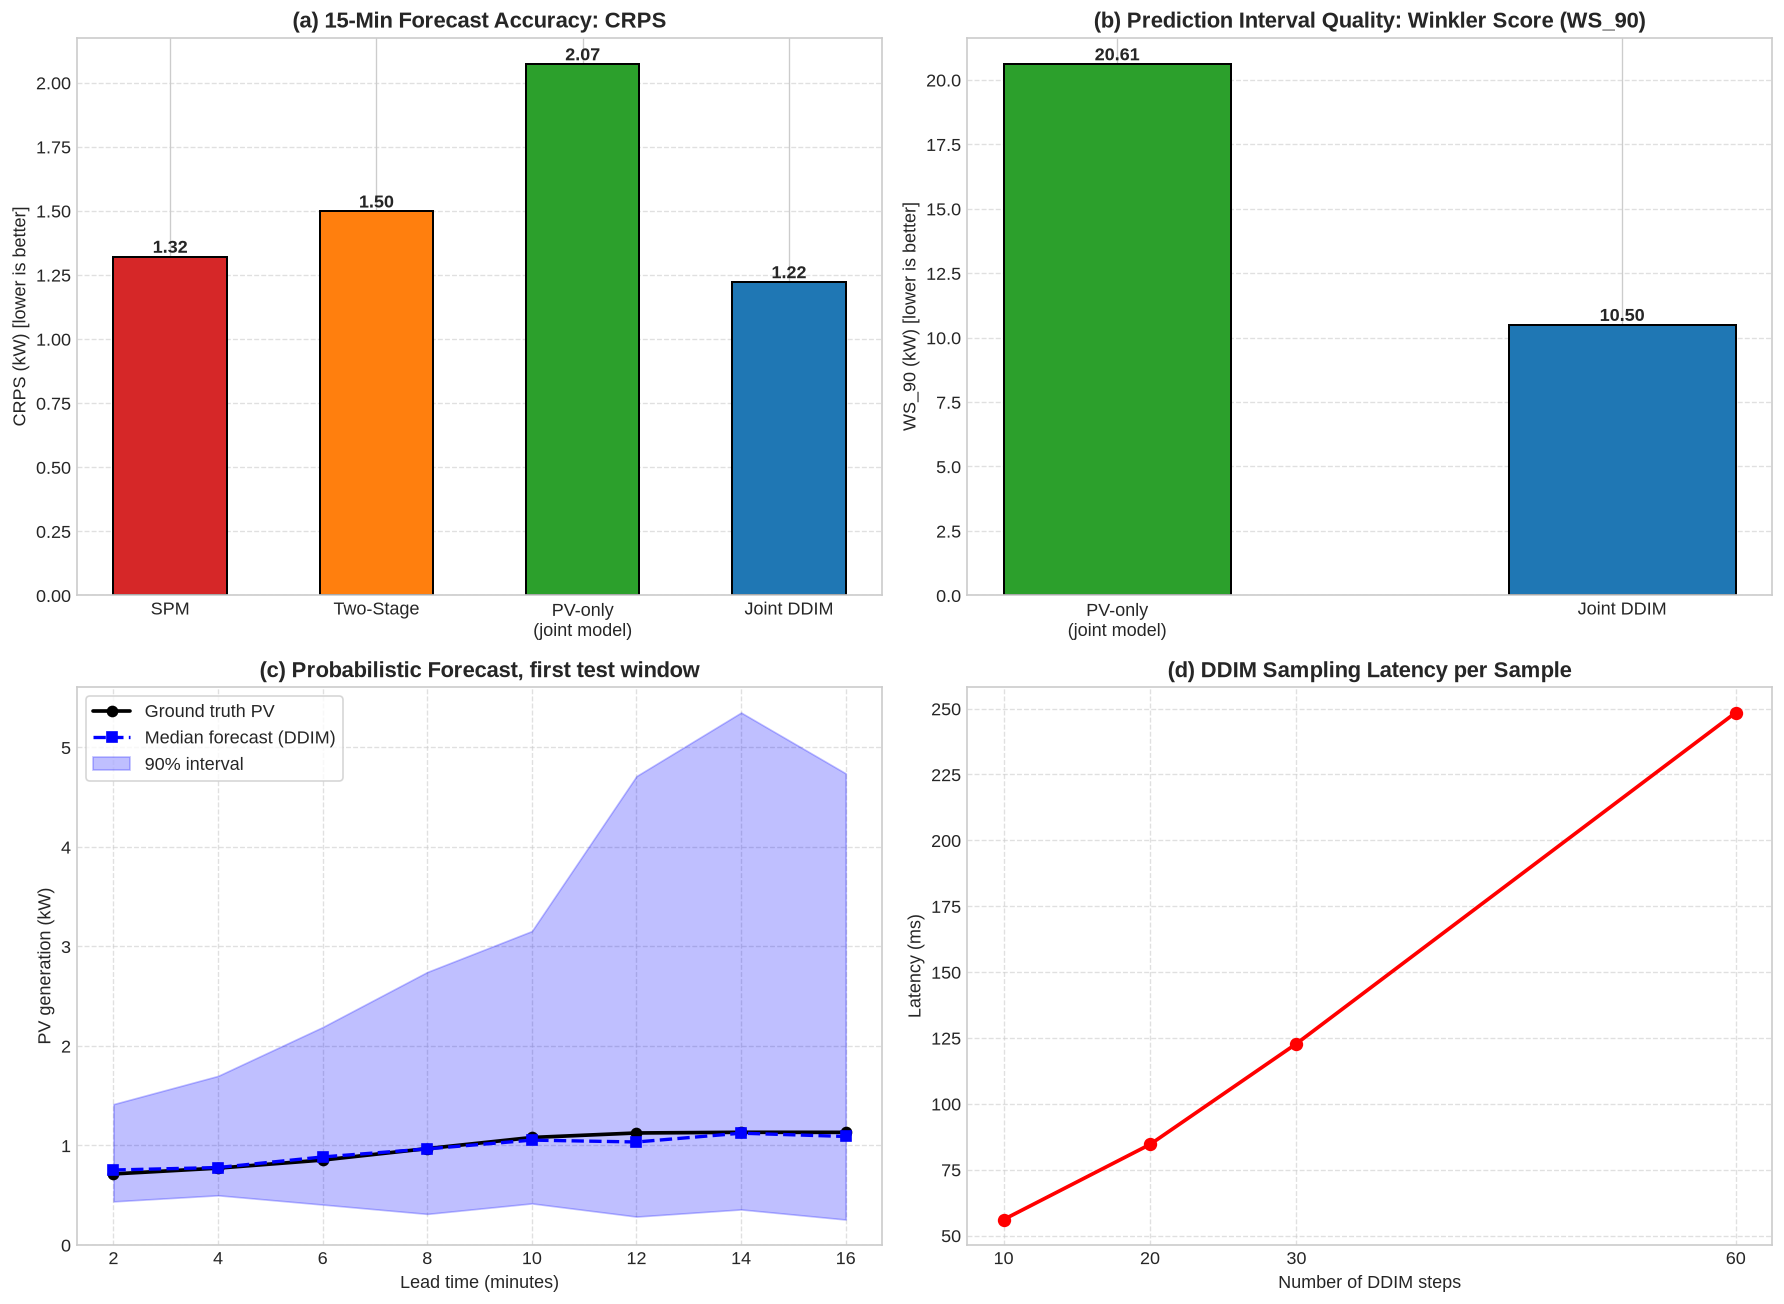

Saved 'ddim_15min_forecasting_results.png'.


In [26]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# (a) CRPS comparison
names = ["SPM", "Two-Stage"]
vals = [r["spm_crps"], r["two_stage_crps"]]
cols = ["#d62728", "#ff7f0e"]
if r["pv_only_crps"] is not None:
    names.append("PV-only\n(joint model)")
    vals.append(r["pv_only_crps"])
    cols.append("#2ca02c")
names.append("Joint DDIM")
vals.append(r["crps_kw"])
cols.append("#1f77b4")

bars = axes[0, 0].bar(
    names, vals, color=cols, width=0.55, edgecolor="black", linewidth=1.2
)
axes[0, 0].set_title("(a) 15-Min Forecast Accuracy: CRPS", fontweight="bold")
axes[0, 0].set_ylabel("CRPS (kW) [lower is better]")
axes[0, 0].grid(axis="y", linestyle="--", alpha=0.6)
for bar in bars:
    y = bar.get_height()
    axes[0, 0].text(
        bar.get_x() + bar.get_width() / 2.0,
        y,
        f"{y:.2f}",
        ha="center",
        va="bottom",
        fontweight="bold",
    )

# (b) Winkler score — probabilistic models only
ws_names, ws_vals, ws_cols = [], [], []
if r["pv_only_ws"] is not None:
    ws_names.append("PV-only\n(joint model)")
    ws_vals.append(r["pv_only_ws"])
    ws_cols.append("#2ca02c")
ws_names.append("Joint DDIM")
ws_vals.append(r["ws_kw"])
ws_cols.append("#1f77b4")
bars_ws = axes[0, 1].bar(
    ws_names, ws_vals, color=ws_cols, width=0.45, edgecolor="black", linewidth=1.2
)
axes[0, 1].set_title(
    "(b) Prediction Interval Quality: Winkler Score (WS_90)", fontweight="bold"
)
axes[0, 1].set_ylabel("WS_90 (kW) [lower is better]")
axes[0, 1].grid(axis="y", linestyle="--", alpha=0.6)
for bar in bars_ws:
    y = bar.get_height()
    axes[0, 1].text(
        bar.get_x() + bar.get_width() / 2.0,
        y,
        f"{y:.2f}",
        ha="center",
        va="bottom",
        fontweight="bold",
    )

# (c) Example probabilistic trajectory (first test window, not cherry-picked)
true_seq = r["pv_true"][0]
ensemble = r["pv_ensemble"][0]
time_steps = np.arange(2, 2 * len(true_seq) + 1, 2)
axes[1, 0].plot(time_steps, true_seq, "k-o", linewidth=2.2, label="Ground truth PV")
axes[1, 0].plot(
    time_steps,
    np.median(ensemble, axis=-1),
    "b--s",
    linewidth=2,
    label="Median forecast (DDIM)",
)
axes[1, 0].fill_between(
    time_steps,
    np.percentile(ensemble, 5, axis=-1),
    np.percentile(ensemble, 95, axis=-1),
    color="blue",
    alpha=0.25,
    label="90% interval",
)
axes[1, 0].set_title("(c) Probabilistic Forecast, first test window", fontweight="bold")
axes[1, 0].set_xlabel("Lead time (minutes)")
axes[1, 0].set_ylabel("PV generation (kW)")
axes[1, 0].set_ylim(bottom=0)
axes[1, 0].legend(frameon=True)
axes[1, 0].grid(True, linestyle="--", alpha=0.6)

# (d) latency vs steps
axes[1, 1].plot(
    list(sweep_results.keys()),
    list(sweep_results.values()),
    "ro-",
    linewidth=2.2,
    markersize=7,
)
axes[1, 1].set_title("(d) DDIM Sampling Latency per Sample", fontweight="bold")
axes[1, 1].set_xlabel("Number of DDIM steps")
axes[1, 1].set_ylabel("Latency (ms)")
axes[1, 1].set_xticks(list(sweep_results.keys()))
axes[1, 1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("ddim_15min_forecasting_results.png", dpi=300)
plt.show()
print("Saved 'ddim_15min_forecasting_results.png'.")


## Cell 21: Results Showcase — Visual Summary of the 15-Minute Forecasts

Fan charts for three representative (automatically selected, not cherry-picked) windows,
CRPS / skill / coverage by lead time, calibration diagnostics, and generated vs. observed sky images.


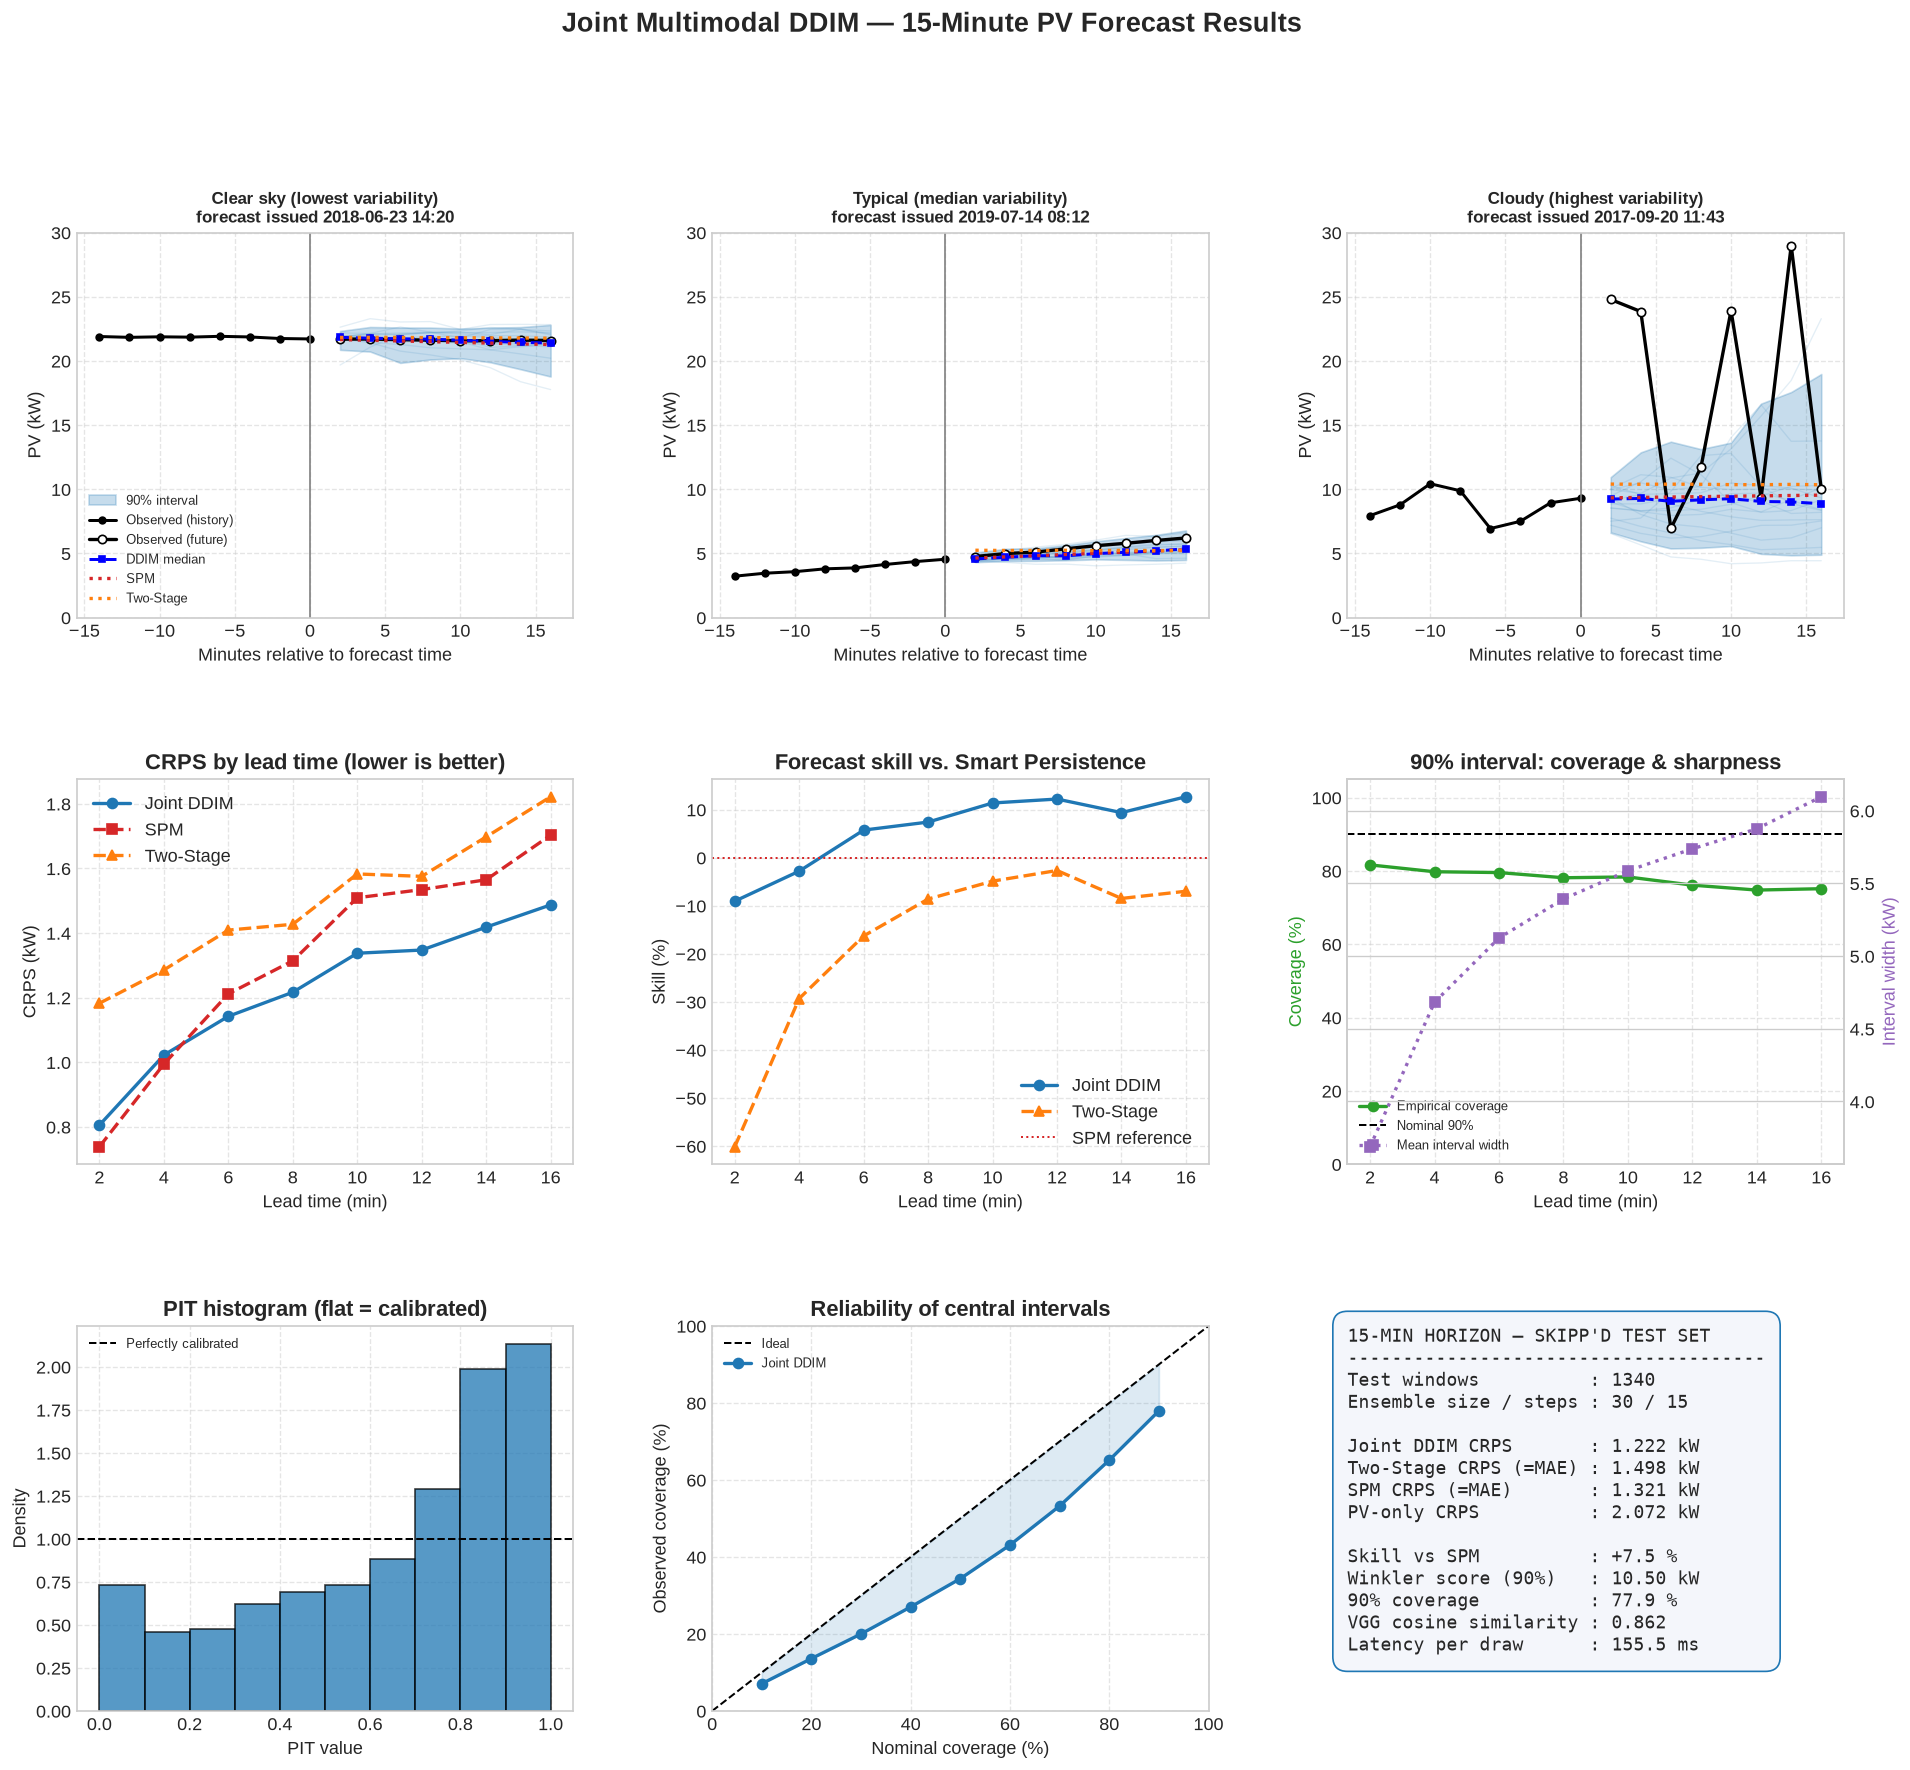

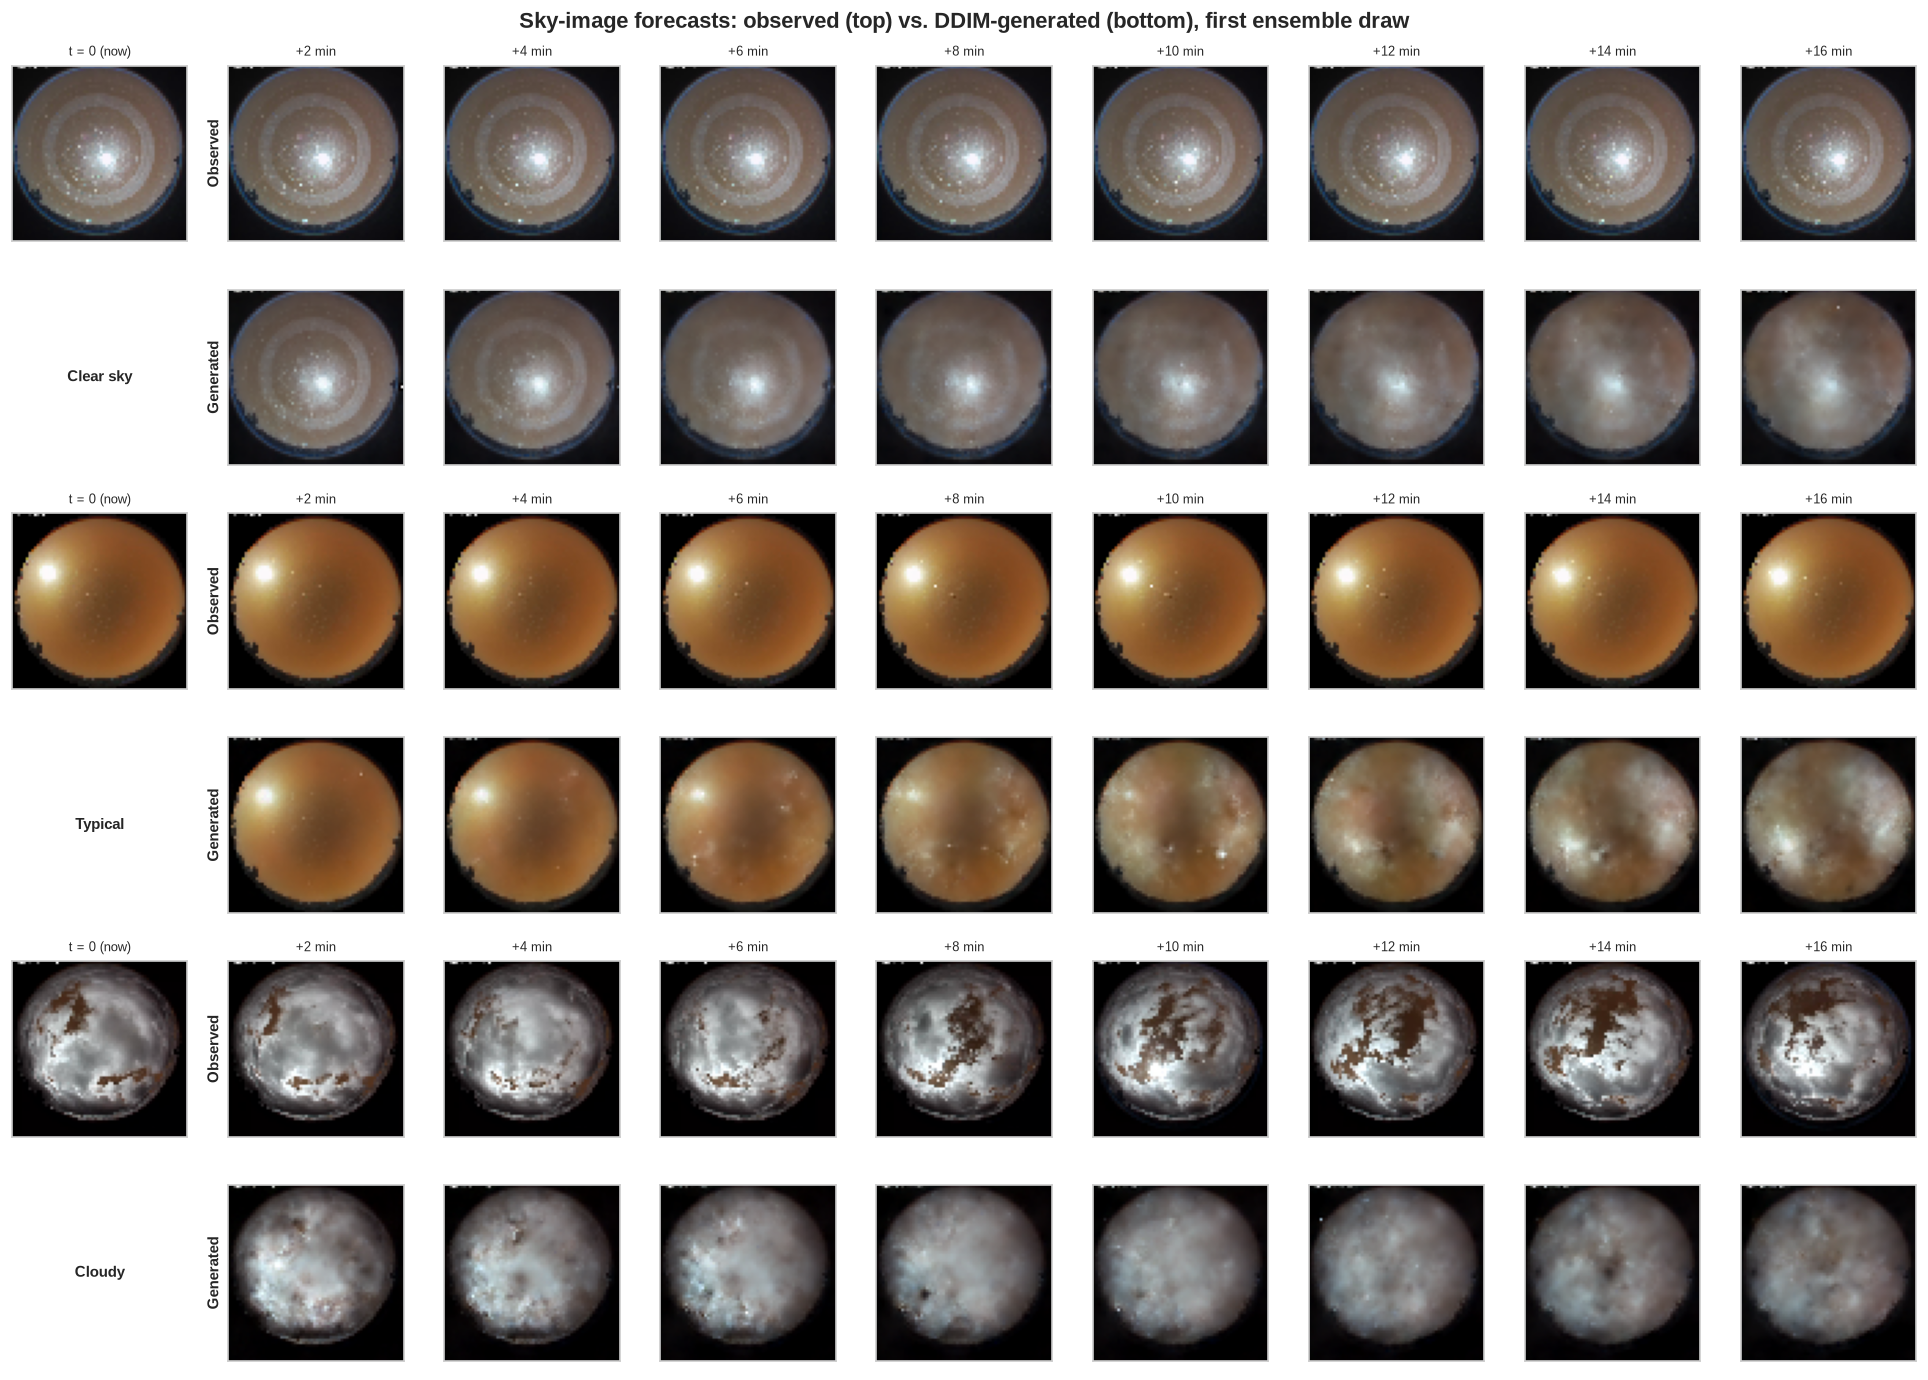

Saved 'showcase_15min_dashboard.png' and 'showcase_15min_sky_images.png'.


In [27]:

import matplotlib.gridspec as gridspec

r = evaluation_results["15min"]
pv_true = np.asarray(r["pv_true"], dtype=np.float64)        # (N, T_f) kW
pv_ens = np.asarray(r["pv_ensemble"], dtype=np.float64)     # (N, T_f, M) kW
N, T_f, M = pv_ens.shape
T_h = cfg.hist_frames
lead_min = np.arange(1, T_f + 1) * cfg.cadence_minutes      # 2, 4, ..., 16 min
hist_min = np.arange(-(T_h - 1), 1) * cfg.cadence_minutes   # -14, ..., 0 min

ens_med = np.median(pv_ens, axis=-1)
ens_p05 = np.percentile(pv_ens, 5, axis=-1)
ens_p95 = np.percentile(pv_ens, 95, axis=-1)
spm_kw = np.asarray(spm_pred_kw, dtype=np.float64).reshape(N, T_f)
two_kw = np.asarray(two_stage_pred_kw, dtype=np.float64).reshape(N, T_f)

# ---- Per-lead-time scores
crps_lead = {
    "Joint DDIM": np.array([compute_crps(pv_true[:, k], pv_ens[:, k, :]) for k in range(T_f)]),
    "SPM": np.array([compute_crps(pv_true[:, k], spm_kw[:, k:k + 1]) for k in range(T_f)]),
    "Two-Stage": np.array([compute_crps(pv_true[:, k], two_kw[:, k:k + 1]) for k in range(T_f)]),
}
skill_lead = {
    name: 100.0 * (1.0 - v / np.maximum(crps_lead["SPM"], 1e-6))
    for name, v in crps_lead.items() if name != "SPM"
}
coverage_lead = np.mean((pv_true >= ens_p05) & (pv_true <= ens_p95), axis=0)
width_lead = np.mean(ens_p95 - ens_p05, axis=0)

# ---- Calibration: reliability of central intervals + randomized PIT
nominal = np.arange(10, 100, 10)
empirical = np.array([
    np.mean((pv_true >= np.percentile(pv_ens, 50 - q / 2, axis=-1))
            & (pv_true <= np.percentile(pv_ens, 50 + q / 2, axis=-1)))
    for q in nominal
])
rng_pit = np.random.default_rng(RANDOM_SEED)
below = (pv_ens < pv_true[..., None]).sum(-1)
ties = (pv_ens == pv_true[..., None]).sum(-1)   # night-time zeros create ties -> randomize
pit = (below + rng_pit.uniform(size=below.shape) * (ties + 1)) / (M + 1)

# ---- Automatic selection of 3 daytime windows by variability
variability = np.abs(
    np.diff(np.concatenate([pv_hist_kw[:, -1:], pv_true], axis=1), axis=1)
).mean(axis=1)
daytime = pv_true.mean(axis=1) > 0.15 * PV_RATED_CAPACITY_KW
cand = np.where(daytime)[0] if daytime.sum() >= 3 else np.arange(N)
v = variability[cand]
showcase = {
    "Clear sky (lowest variability)": int(cand[np.argmin(v)]),
    "Typical (median variability)": int(cand[np.argsort(v)[len(v) // 2]]),
    "Cloudy (highest variability)": int(cand[np.argmax(v)]),
}

# =====================================================================
# FIGURE 1: forecast dashboard
# =====================================================================
fig = plt.figure(figsize=(19, 16))
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.42, wspace=0.28)

# Row 0: fan charts
for j, (label, i) in enumerate(showcase.items()):
    ax = fig.add_subplot(gs[0, j])
    for m in range(min(M, 15)):
        ax.plot(lead_min, pv_ens[i, :, m], color="tab:blue", alpha=0.12, lw=0.8)
    ax.fill_between(lead_min, ens_p05[i], ens_p95[i], color="tab:blue", alpha=0.25, label="90% interval")
    ax.plot(hist_min, pv_hist_kw[i], "k-o", ms=4, lw=1.8, label="Observed (history)")
    ax.plot(lead_min, pv_true[i], "k-o", mfc="white", ms=5, lw=2, label="Observed (future)")
    ax.plot(lead_min, ens_med[i], "b--s", ms=4, lw=1.8, label="DDIM median")
    ax.plot(lead_min, spm_kw[i], ":", color="tab:red", lw=2, label="SPM")
    ax.plot(lead_min, two_kw[i], ":", color="tab:orange", lw=2, label="Two-Stage")
    ax.axvline(0, color="grey", lw=1)
    t_now = pd.to_datetime(hist_times_te[i, -1])
    ax.set_title(f"{label}\nforecast issued {t_now:%Y-%m-%d %H:%M}", fontsize=10, fontweight="bold")
    ax.set_xlabel("Minutes relative to forecast time")
    ax.set_ylabel("PV (kW)")
    ax.set_ylim(0, PV_RATED_CAPACITY_KW)
    ax.grid(True, linestyle="--", alpha=0.5)
    if j == 0:
        ax.legend(fontsize=8, loc="lower left")

# Row 1: CRPS by lead, skill by lead, coverage/width by lead
ax = fig.add_subplot(gs[1, 0])
styles = {"Joint DDIM": ("tab:blue", "o-"), "SPM": ("tab:red", "s--"), "Two-Stage": ("tab:orange", "^--")}
for name, vals in crps_lead.items():
    c, st = styles[name]
    ax.plot(lead_min, vals, st, color=c, lw=2, label=name)
ax.set_title("CRPS by lead time (lower is better)", fontweight="bold")
ax.set_xlabel("Lead time (min)"); ax.set_ylabel("CRPS (kW)")
ax.legend(); ax.grid(True, linestyle="--", alpha=0.5)

ax = fig.add_subplot(gs[1, 1])
for name, vals in skill_lead.items():
    c, st = styles[name]
    ax.plot(lead_min, vals, st, color=c, lw=2, label=name)
ax.axhline(0, color="tab:red", lw=1.2, ls=":", label="SPM reference")
ax.set_title("Forecast skill vs. Smart Persistence", fontweight="bold")
ax.set_xlabel("Lead time (min)"); ax.set_ylabel("Skill (%)")
ax.legend(); ax.grid(True, linestyle="--", alpha=0.5)

ax = fig.add_subplot(gs[1, 2])
ax.plot(lead_min, coverage_lead * 100, "o-", color="tab:green", lw=2, label="Empirical coverage")
ax.axhline(90, color="k", ls="--", lw=1.2, label="Nominal 90%")
ax.set_ylim(0, 105)
ax.set_xlabel("Lead time (min)"); ax.set_ylabel("Coverage (%)", color="tab:green")
ax2 = ax.twinx()
ax2.plot(lead_min, width_lead, "s:", color="tab:purple", lw=2, label="Mean interval width")
ax2.set_ylabel("Interval width (kW)", color="tab:purple")
ax.set_title("90% interval: coverage & sharpness", fontweight="bold")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="lower left"); ax.grid(True, linestyle="--", alpha=0.5)

# Row 2: PIT histogram, reliability diagram, summary panel
ax = fig.add_subplot(gs[2, 0])
ax.hist(pit.ravel(), bins=10, range=(0, 1), density=True, color="tab:blue", edgecolor="black", alpha=0.75)
ax.axhline(1.0, color="k", ls="--", lw=1.2, label="Perfectly calibrated")
ax.set_title("PIT histogram (flat = calibrated)", fontweight="bold")
ax.set_xlabel("PIT value"); ax.set_ylabel("Density"); ax.legend(fontsize=8)
ax.grid(True, linestyle="--", alpha=0.5)

ax = fig.add_subplot(gs[2, 1])
ax.plot([0, 100], [0, 100], "k--", lw=1.2, label="Ideal")
ax.plot(nominal, empirical * 100, "o-", color="tab:blue", lw=2, label="Joint DDIM")
ax.fill_between(nominal, nominal, empirical * 100, color="tab:blue", alpha=0.15)
ax.set_title("Reliability of central intervals", fontweight="bold")
ax.set_xlabel("Nominal coverage (%)"); ax.set_ylabel("Observed coverage (%)")
ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.legend(fontsize=8)
ax.grid(True, linestyle="--", alpha=0.5)

ax = fig.add_subplot(gs[2, 2]); ax.axis("off")
summary = (
    f"15-MIN HORIZON — SKIPP'D TEST SET\n"
    f"{'-' * 38}\n"
    f"Test windows          : {r['n_windows']}\n"
    f"Ensemble size / steps : {r['m_samples']} / {r['ddim_steps']}\n\n"
    f"Joint DDIM CRPS       : {r['crps_kw']:.3f} kW\n"
    f"Two-Stage CRPS (=MAE) : {r['two_stage_crps']:.3f} kW\n"
    f"SPM CRPS (=MAE)       : {r['spm_crps']:.3f} kW\n"
    + (f"PV-only CRPS          : {r['pv_only_crps']:.3f} kW\n" if r["pv_only_crps"] is not None else "")
    + f"\nSkill vs SPM          : {r['fs_percent']:+.1f} %\n"
    f"Winkler score (90%)   : {r['ws_kw']:.2f} kW\n"
    f"90% coverage          : {r['coverage_90'] * 100:.1f} %\n"
    f"VGG cosine similarity : {r['vgg_cs']:.3f}\n"
    f"Latency per draw      : {r['latency_ms']:.1f} ms"
)
ax.text(0.0, 1.0, summary, va="top", ha="left", family="monospace", fontsize=11,
        bbox=dict(boxstyle="round,pad=0.8", facecolor="#f4f6fb", edgecolor="#1f77b4"))

fig.suptitle("Joint Multimodal DDIM — 15-Minute PV Forecast Results", fontsize=16, fontweight="bold", y=0.995)
plt.savefig("showcase_15min_dashboard.png", dpi=250, bbox_inches="tight")
plt.show()

# =====================================================================
# FIGURE 2: observed vs generated sky images for the same windows
# =====================================================================
n_cols = T_f + 1
n_rows = 2 * len(showcase)
fig2, axes2 = plt.subplots(n_rows, n_cols, figsize=(1.8 * n_cols, 1.95 * n_rows))
for j, (label, i) in enumerate(showcase.items()):
    now_img = denormalize_images(img_hist_norm[i, -1])
    true_imgs = denormalize_images(img_true_norm[i])
    gen_imgs = denormalize_images(sample_img_first[i])
    for row, (imgs, name) in enumerate([(true_imgs, "Observed"), (gen_imgs, "Generated")]):
        rr = 2 * j + row
        for c in range(n_cols):
            ax = axes2[rr, c]
            ax.set_xticks([]); ax.set_yticks([])
            if c == 0:
                if row == 0:
                    ax.imshow(now_img)
                    ax.set_title("t = 0 (now)", fontsize=8)
                else:
                    ax.axis("off")
                    ax.text(0.5, 0.5, label.split(" (")[0], ha="center", va="center",
                            fontsize=9, fontweight="bold", transform=ax.transAxes)
            else:
                ax.imshow(imgs[c - 1])
                if rr == 0 or row == 0:
                    ax.set_title(f"+{lead_min[c - 1]} min", fontsize=8)
            if c == 1:
                ax.set_ylabel(name, fontsize=9, fontweight="bold")
fig2.suptitle("Sky-image forecasts: observed (top) vs. DDIM-generated (bottom), first ensemble draw",
              fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("showcase_15min_sky_images.png", dpi=250, bbox_inches="tight")
plt.show()
print("Saved 'showcase_15min_dashboard.png' and 'showcase_15min_sky_images.png'.")

## Cell 22: Forecasted vs. Observed (Original) Values

Point-error metrics, scatter plots against the 1:1 line, error distributions, error by lead time,
sky-image fidelity vs. an image-persistence baseline, and full-day time series against the raw
1-minute measurements. Everything is exported to CSV.


FORECAST vs OBSERVED — POINT-ERROR METRICS (all test windows)
                     MAE (kW)  RMSE (kW)  MBE (kW)  nRMSE (% cap.)     R²  Pearson r
Joint DDIM (median)     1.684      2.960    -0.763           9.866  0.838      0.921
Joint DDIM (mean)       1.823      2.956    -0.837           9.853  0.839      0.923
Smart Persistence       1.321      3.087    -0.035          10.289  0.824      0.912
Two-Stage               1.498      2.838     0.172           9.461  0.851      0.923

Daytime windows only (mean observed PV > 15% of capacity):
                     MAE (kW)  RMSE (kW)  MBE (kW)  nRMSE (% cap.)     R²  Pearson r
Joint DDIM (median)     1.899      3.209    -0.954          10.698  0.716      0.865
Joint DDIM (mean)       2.046      3.195    -1.083          10.651  0.719      0.868
Smart Persistence       1.481      3.354    -0.048          11.181  0.690      0.845
Two-Stage               1.608      3.045     0.090          10.151  0.745      0.864

MAE (kW) by lead time:
    

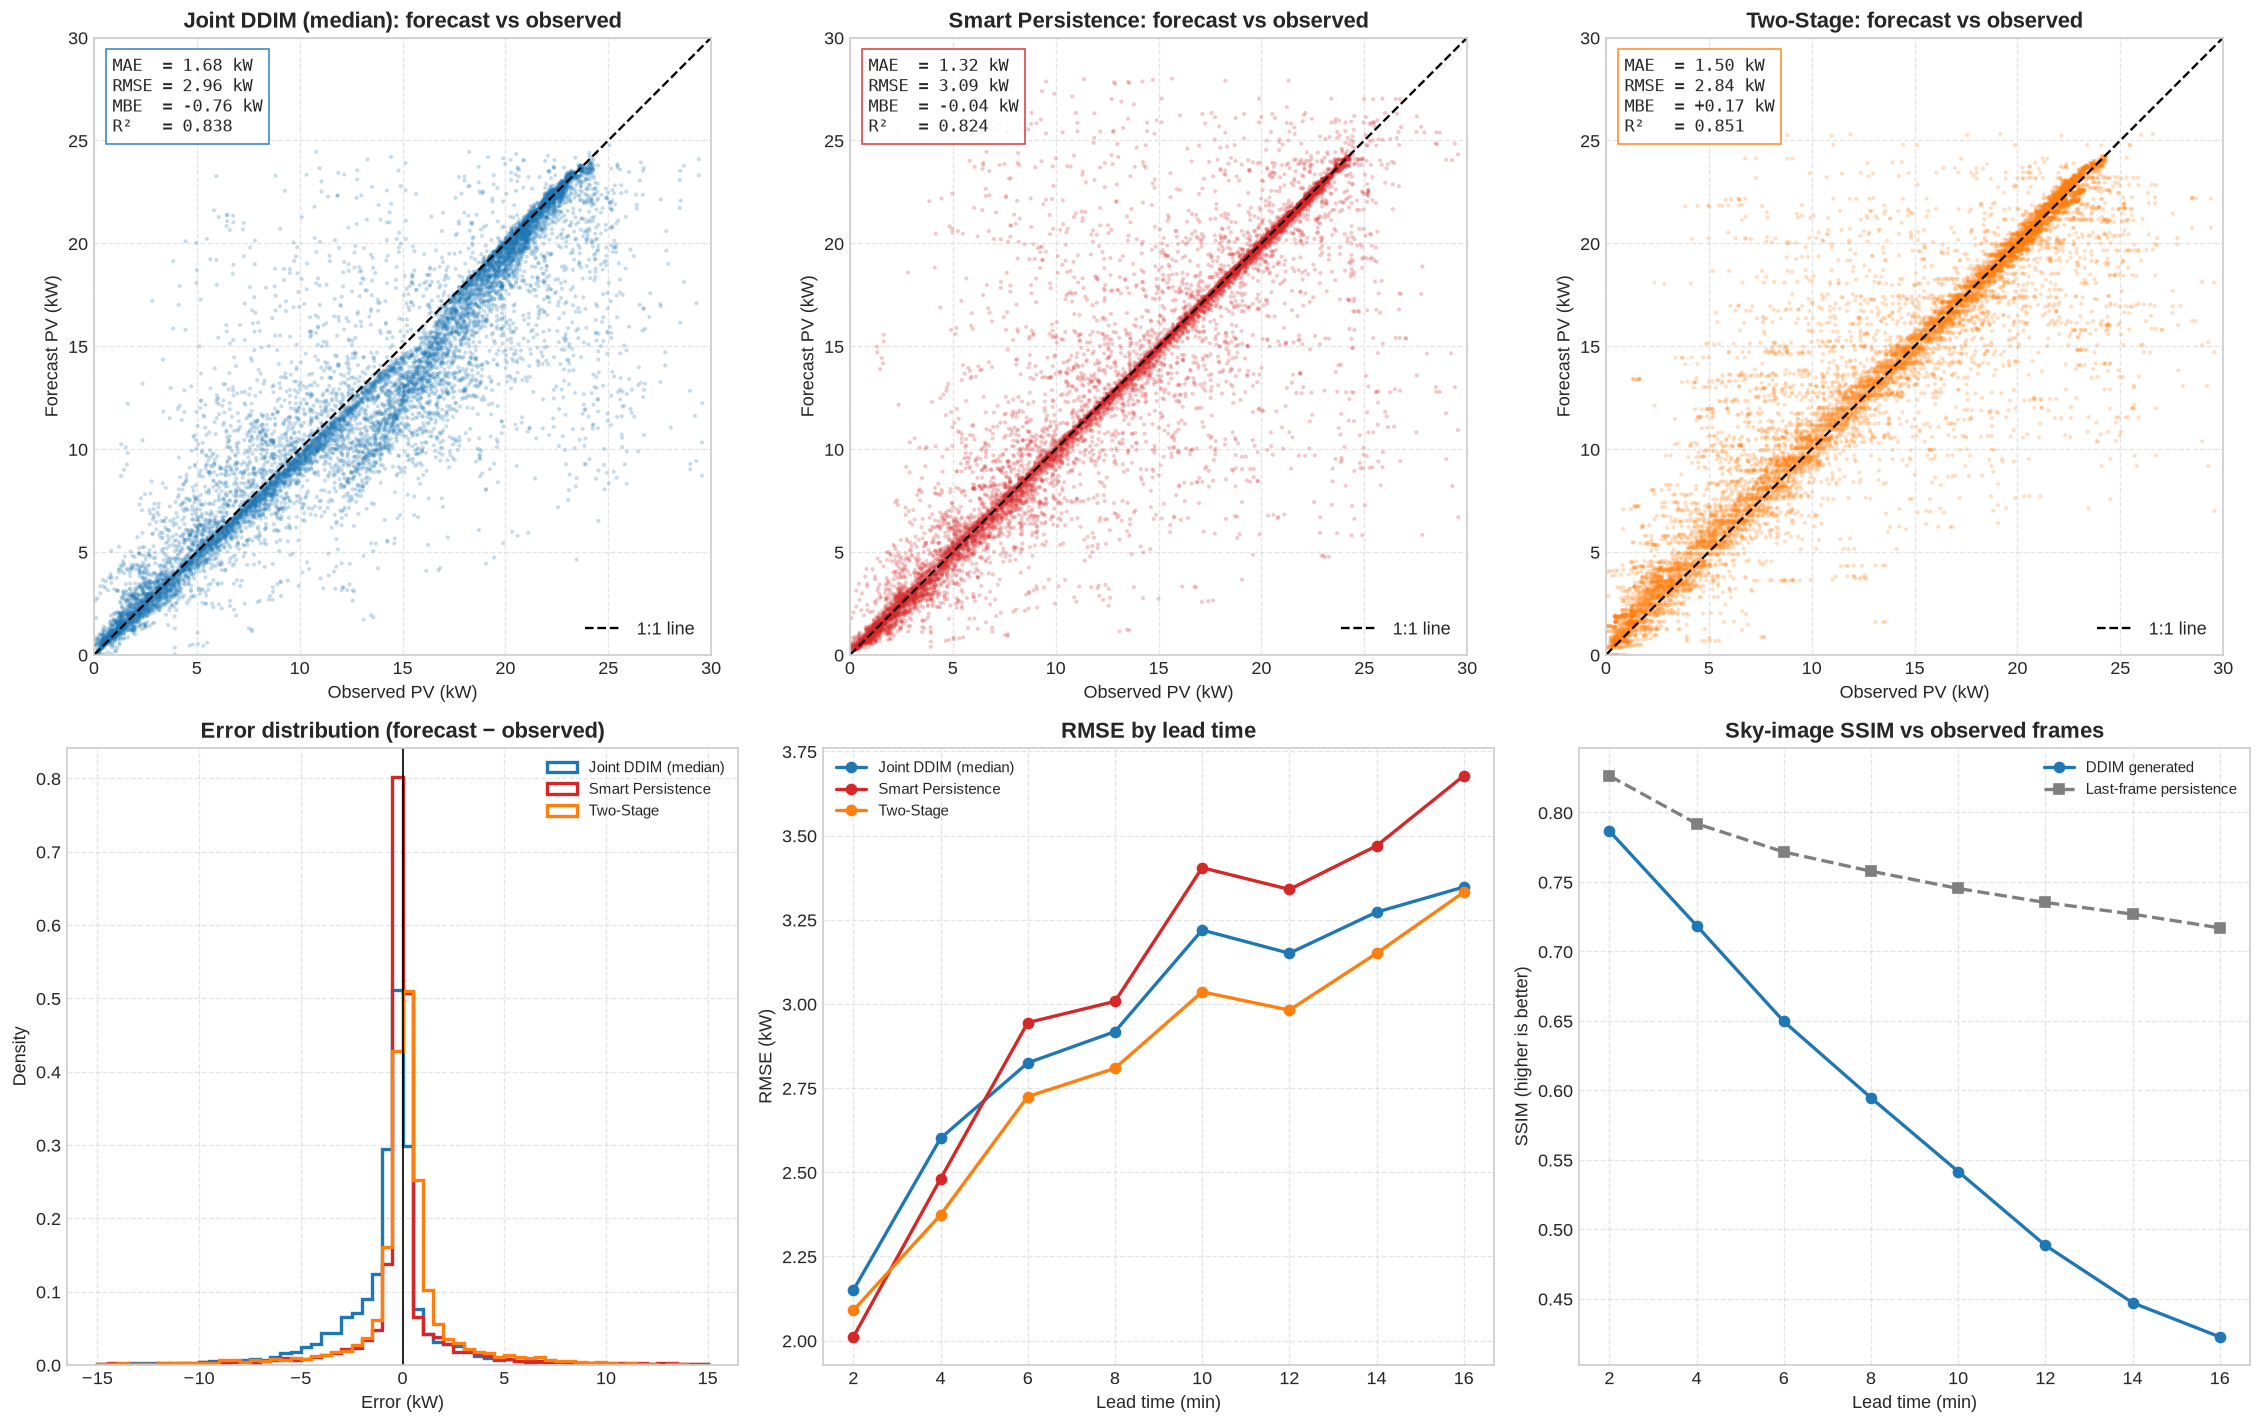

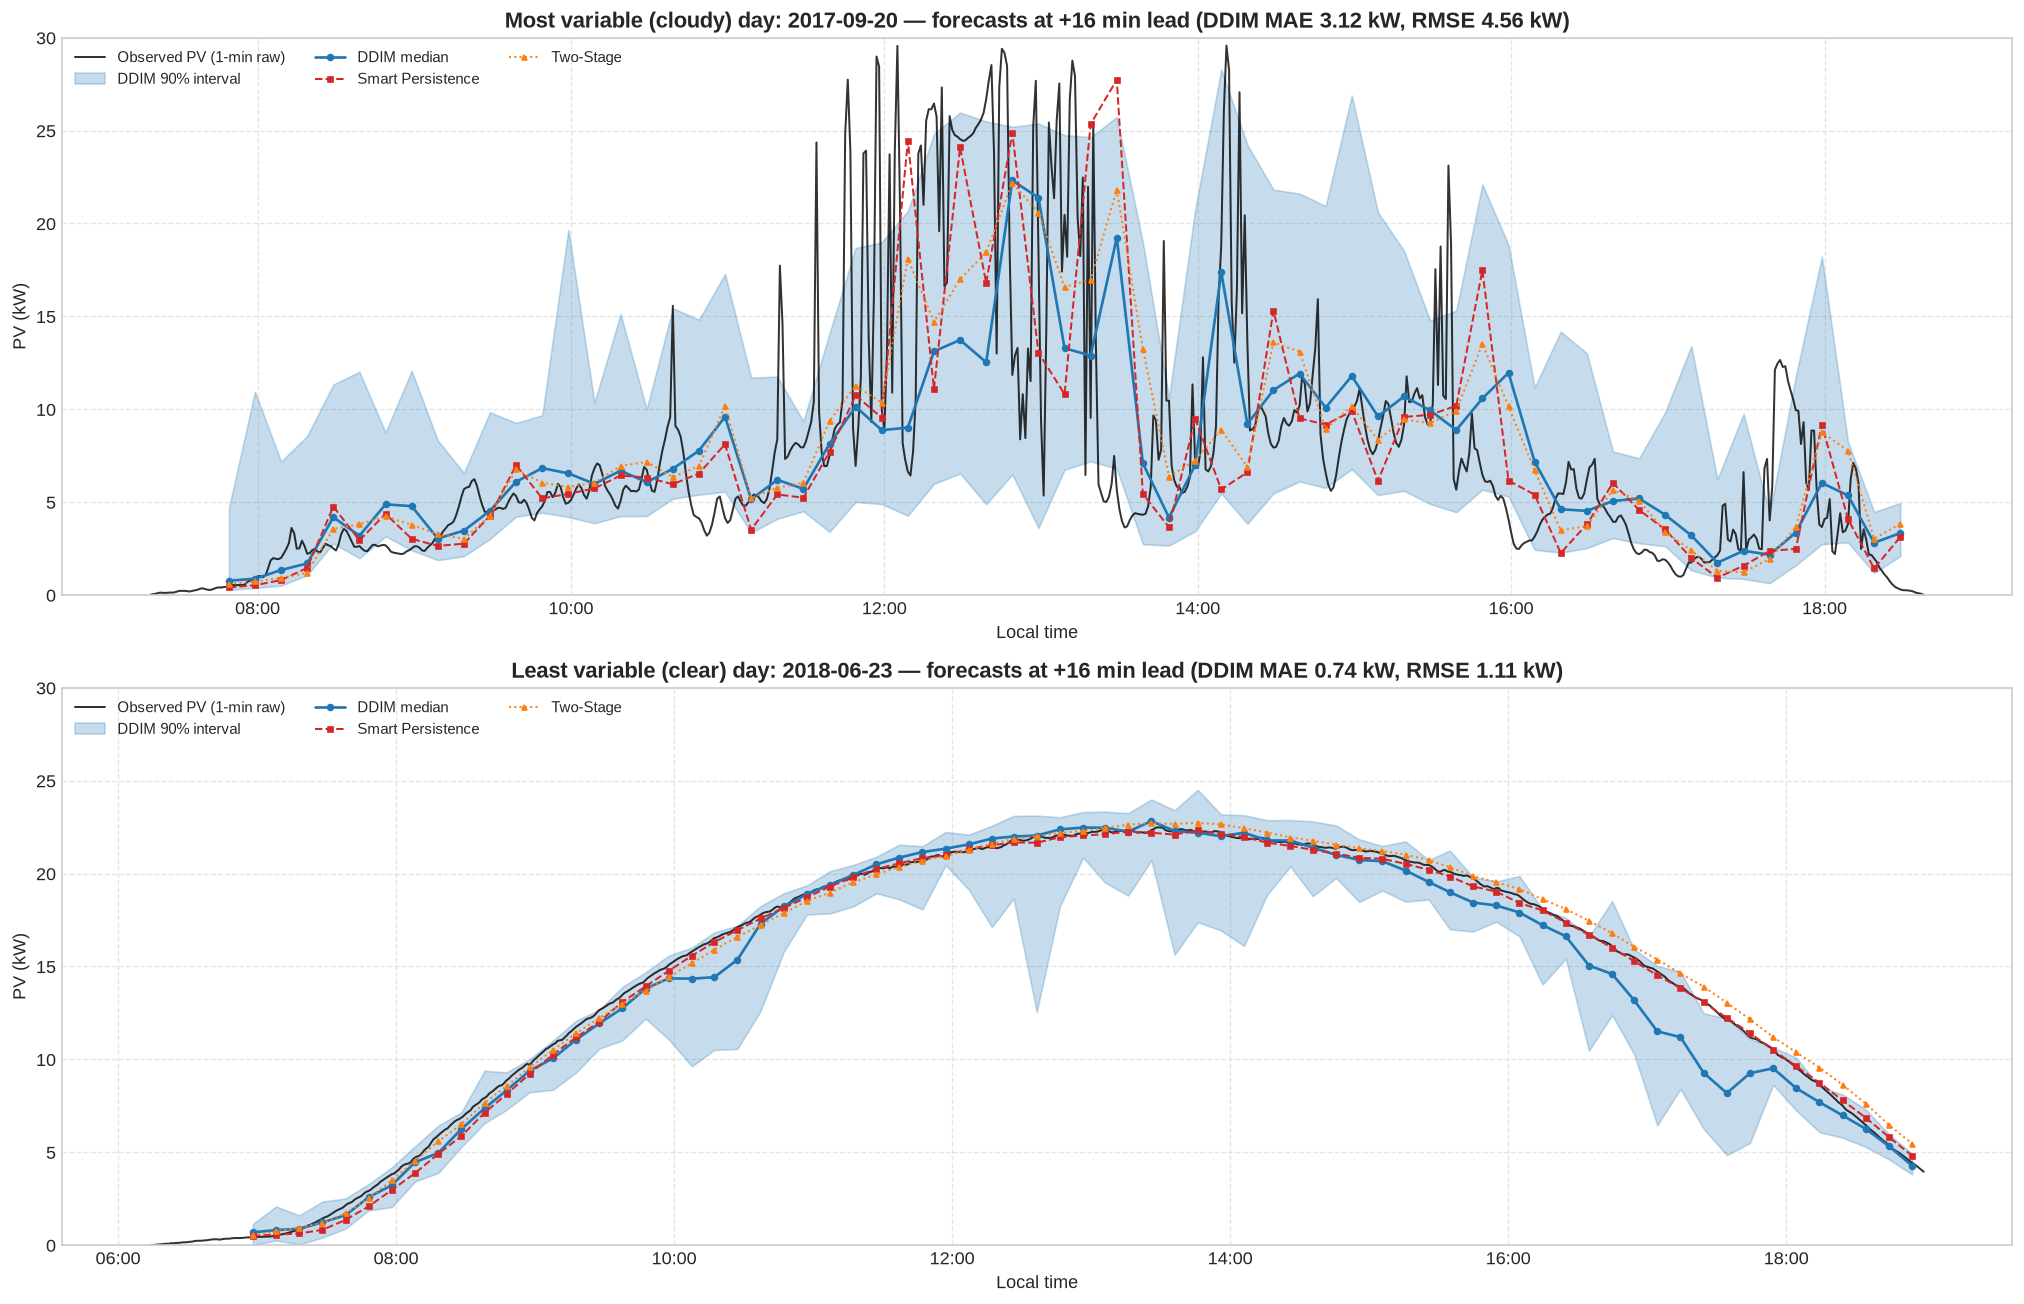


Saved figures: comparison_15min_forecast_vs_observed.png, comparison_15min_daily_timeseries.png
Saved tables : forecast_vs_observed_15min.csv, point_metrics_15min.csv, mae_by_lead_15min.csv


In [28]:
def det_scores(y, yhat):
    y, yhat = np.ravel(y), np.ravel(yhat)
    err = yhat - y
    sst = np.sum((y - y.mean()) ** 2)
    return {
        "MAE (kW)": np.mean(np.abs(err)),
        "RMSE (kW)": np.sqrt(np.mean(err ** 2)),
        "MBE (kW)": np.mean(err),
        "nRMSE (% cap.)": 100 * np.sqrt(np.mean(err ** 2)) / PV_RATED_CAPACITY_KW,
        "R²": 1 - np.sum(err ** 2) / max(sst, 1e-12),
        "Pearson r": np.corrcoef(y, yhat)[0, 1] if np.std(yhat) > 0 else np.nan,
    }


forecasts = {
    "Joint DDIM (median)": ens_med,
    "Joint DDIM (mean)": pv_ens.mean(axis=-1),
    "Smart Persistence": spm_kw,
    "Two-Stage": two_kw,
}

# ---- 1. Overall and daytime-only error tables
print("=" * 90)
print("FORECAST vs OBSERVED — POINT-ERROR METRICS (all test windows)")
print("=" * 90)
df_all = pd.DataFrame({k: det_scores(pv_true, v) for k, v in forecasts.items()}).T
print(df_all.round(3).to_string())

print("\nDaytime windows only (mean observed PV > 15% of capacity):")
df_day = pd.DataFrame({k: det_scores(pv_true[daytime], v[daytime]) for k, v in forecasts.items()}).T
print(df_day.round(3).to_string())

# ---- 2. MAE by lead time
df_lead = pd.DataFrame(
    {k: np.mean(np.abs(v - pv_true), axis=0) for k, v in forecasts.items()},
    index=[f"+{m} min" for m in lead_min],
)
print("\nMAE (kW) by lead time:")
print(df_lead.round(3).to_string())

# ---- 3. Sky-image fidelity per lead: generated vs observed, and 'last frame persists' baseline
with tf.device("/CPU:0"):
    ssim_gen, ssim_pers, mae_gen, mae_pers = [], [], [], []
    last_frame = tf.constant(img_hist_norm[:, -1], tf.float32)
    for k in range(T_f):
        true_k = tf.constant(img_true_norm[:, k], tf.float32)
        gen_k = tf.constant(sample_img_first[:, k], tf.float32)
        ssim_gen.append(float(tf.reduce_mean(tf.image.ssim(gen_k, true_k, max_val=2.0))))
        ssim_pers.append(float(tf.reduce_mean(tf.image.ssim(last_frame, true_k, max_val=2.0))))
        mae_gen.append(float(tf.reduce_mean(tf.abs(gen_k - true_k))) * 127.5)
        mae_pers.append(float(tf.reduce_mean(tf.abs(last_frame - true_k))) * 127.5)
print("\nSky-image comparison (mean over test windows):")
print(pd.DataFrame(
    {"SSIM generated": ssim_gen, "SSIM persistence": ssim_pers,
     "Pixel MAE generated": mae_gen, "Pixel MAE persistence": mae_pers},
    index=[f"+{m} min" for m in lead_min],
).round(3).to_string())

# =====================================================================
# FIGURE 3: forecast vs observed diagnostics
# =====================================================================
fig, axes = plt.subplots(2, 3, figsize=(19, 12))
scatter_models = [("Joint DDIM (median)", "tab:blue"), ("Smart Persistence", "tab:red"), ("Two-Stage", "tab:orange")]

for ax, (name, color) in zip(axes[0], scatter_models):
    pred = forecasts[name]
    ax.scatter(pv_true.ravel(), pred.ravel(), s=6, alpha=0.25, color=color, edgecolors="none")
    ax.plot([0, PV_RATED_CAPACITY_KW], [0, PV_RATED_CAPACITY_KW], "k--", lw=1.4, label="1:1 line")
    s = det_scores(pv_true, pred)
    ax.text(0.03, 0.97, f"MAE  = {s['MAE (kW)']:.2f} kW\nRMSE = {s['RMSE (kW)']:.2f} kW\n"
                        f"MBE  = {s['MBE (kW)']:+.2f} kW\nR²   = {s['R²']:.3f}",
            transform=ax.transAxes, va="top", family="monospace", fontsize=10,
            bbox=dict(facecolor="white", alpha=0.85, edgecolor=color))
    ax.set_xlim(0, PV_RATED_CAPACITY_KW); ax.set_ylim(0, PV_RATED_CAPACITY_KW)
    ax.set_aspect("equal")
    ax.set_title(f"{name}: forecast vs observed", fontweight="bold")
    ax.set_xlabel("Observed PV (kW)"); ax.set_ylabel("Forecast PV (kW)")
    ax.legend(loc="lower right"); ax.grid(True, linestyle="--", alpha=0.5)

# Error distributions
ax = axes[1, 0]
bins = np.linspace(-15, 15, 61)
for name, color in scatter_models:
    ax.hist((forecasts[name] - pv_true).ravel(), bins=bins, histtype="step", lw=2, color=color,
            density=True, label=name)
ax.axvline(0, color="k", lw=1)
ax.set_title("Error distribution (forecast − observed)", fontweight="bold")
ax.set_xlabel("Error (kW)"); ax.set_ylabel("Density"); ax.legend(fontsize=9)
ax.grid(True, linestyle="--", alpha=0.5)

# RMSE by lead time
ax = axes[1, 1]
for name, color in scatter_models:
    rmse_k = np.sqrt(np.mean((forecasts[name] - pv_true) ** 2, axis=0))
    ax.plot(lead_min, rmse_k, "o-", color=color, lw=2, label=name)
ax.set_title("RMSE by lead time", fontweight="bold")
ax.set_xlabel("Lead time (min)"); ax.set_ylabel("RMSE (kW)"); ax.legend(fontsize=9)
ax.grid(True, linestyle="--", alpha=0.5)

# Image fidelity by lead time
ax = axes[1, 2]
ax.plot(lead_min, ssim_gen, "o-", color="tab:blue", lw=2, label="DDIM generated")
ax.plot(lead_min, ssim_pers, "s--", color="tab:gray", lw=2, label="Last-frame persistence")
ax.set_title("Sky-image SSIM vs observed frames", fontweight="bold")
ax.set_xlabel("Lead time (min)"); ax.set_ylabel("SSIM (higher is better)")
ax.legend(fontsize=9); ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("comparison_15min_forecast_vs_observed.png", dpi=250, bbox_inches="tight")
plt.show()

# =====================================================================
# FIGURE 4: full-day time series against the raw 1-minute measurements
# =====================================================================
valid_times = pd.to_datetime(np.asarray(r["times_fut"]).ravel()).values.reshape(N, T_f)
test_times_dt = pd.to_datetime(times_test_raw)
test_dates = np.asarray(test_times_dt.date)

uniq_days, counts = np.unique(dates_te, return_counts=True)
eligible = counts >= max(10, counts.max() // 3)
day_var = np.array([variability[dates_te == d].mean() for d in uniq_days])
elig_idx = np.where(eligible)[0] if eligible.any() else np.arange(len(uniq_days))
days_to_plot = {
    "Most variable (cloudy) day": uniq_days[elig_idx[np.argmax(day_var[elig_idx])]],
    "Least variable (clear) day": uniq_days[elig_idx[np.argmin(day_var[elig_idx])]],
}

k_show = T_f - 1  # longest lead (~15-16 min ahead)
fig, axes = plt.subplots(len(days_to_plot), 1, figsize=(17, 5.5 * len(days_to_plot)))
axes = np.atleast_1d(axes)
for ax, (label, d) in zip(axes, days_to_plot.items()):
    raw_mask = test_dates == d
    ax.plot(test_times_dt[raw_mask], test_pv_raw[raw_mask], color="black", lw=1.2, alpha=0.8,
            label="Observed PV (1-min raw)")

    idx = np.where(dates_te == d)[0]
    idx = idx[np.argsort(valid_times[idx, k_show])]
    t = valid_times[idx, k_show]
    ax.fill_between(t, ens_p05[idx, k_show], ens_p95[idx, k_show], color="tab:blue", alpha=0.25,
                    label="DDIM 90% interval")
    ax.plot(t, ens_med[idx, k_show], "o-", color="tab:blue", ms=3.5, lw=1.6, label="DDIM median")
    ax.plot(t, spm_kw[idx, k_show], "s--", color="tab:red", ms=3, lw=1.2, label="Smart Persistence")
    ax.plot(t, two_kw[idx, k_show], "^:", color="tab:orange", ms=3, lw=1.2, label="Two-Stage")

    s_day = det_scores(pv_true[idx, k_show], ens_med[idx, k_show])
    ax.set_title(f"{label}: {d} — forecasts at +{lead_min[k_show]} min lead "
                 f"(DDIM MAE {s_day['MAE (kW)']:.2f} kW, RMSE {s_day['RMSE (kW)']:.2f} kW)",
                 fontweight="bold")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.set_xlabel("Local time"); ax.set_ylabel("PV (kW)")
    ax.set_ylim(0, PV_RATED_CAPACITY_KW)
    ax.legend(loc="upper left", fontsize=9, ncol=3); ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("comparison_15min_daily_timeseries.png", dpi=250, bbox_inches="tight")
plt.show()

# ---- Export per-window, per-lead comparison
df_export = pd.DataFrame({
    "window_id": np.repeat(np.arange(N), T_f),
    "valid_time": valid_times.ravel(),
    "lead_min": np.tile(lead_min, N),
    "observed_kw": pv_true.ravel(),
    "ddim_median_kw": ens_med.ravel(),
    "ddim_mean_kw": pv_ens.mean(axis=-1).ravel(),
    "ddim_p05_kw": ens_p05.ravel(),
    "ddim_p95_kw": ens_p95.ravel(),
    "spm_kw": spm_kw.ravel(),
    "two_stage_kw": two_kw.ravel(),
})
df_export["ddim_error_kw"] = df_export["ddim_median_kw"] - df_export["observed_kw"]
df_export["inside_90pct"] = (df_export["observed_kw"] >= df_export["ddim_p05_kw"]) & \
                            (df_export["observed_kw"] <= df_export["ddim_p95_kw"])
df_export.to_csv("forecast_vs_observed_15min.csv", index=False)
df_all.to_csv("point_metrics_15min.csv")
df_lead.to_csv("mae_by_lead_15min.csv")
print("\nSaved figures: comparison_15min_forecast_vs_observed.png, comparison_15min_daily_timeseries.png")
print("Saved tables : forecast_vs_observed_15min.csv, point_metrics_15min.csv, mae_by_lead_15min.csv")